# 06 · Audio and Video Generation

This is a module of Neural Networks 1002. It assumes [module 05 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/05-diffusion-models/) (diffusion models), [module 04 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/04-autoencoders-gans-and-self-supervised/) (autoencoders and discrete latent codes), [module 05 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) (convolutions) and [module 09 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) (the Transformer).

An image is a grid. **Sound** is a very long list of numbers (16,000 or more per second) in which almost everything interesting lives at two time scales at once: a few milliseconds (the pitch and timbre) and a few seconds (a melody, a sentence). **Video** is a stack of images in which the same object must stay the same object from one frame to the next. Both problems are hard for the same reason: the data are huge and highly structured in time. The field solved them by the trick of this module: **do not generate the raw signal; generate a compact representation (a spectrogram, a sequence of discrete codes, a space-time latent) and decode it**.

An honest warning first. A laptop (or even the 32-core machine that runs this notebook) cannot train an audio or video generator that anyone would want to listen to or watch. So each topic has two parts: a **toy built from scratch** that shows the mechanism and lets us *measure* it, and a **real pre-trained model** run on the CPU so you see what the real thing does. The video toys are illustrative only: tiny moving shapes, not natural video.

In this notebook you will:

* synthesise sounds in code and look at them as a **waveform**, an **STFT** (short-time Fourier transform), a **mel spectrogram**, and as the **discrete tokens** of a real neural audio codec (EnCodec), with a measured bitrate-versus-quality table;
* implement **Griffin-Lim** phase recovery by hand and compare it with a **pre-trained neural vocoder (HiFi-GAN)** on the same signal;
* train, on generated drum and tone sounds, an **autoregressive model over discrete tokens** and a small **diffusion model over spectrograms**, and compare them with a sound-type classifier and a **Fréchet distance**;
* generate a few seconds of music with a **real pre-trained model (MusicGen small)** from text and look at it critically, then discuss how to **evaluate** generated audio (Fréchet audio distance, listening tests);
* train a **next-frame predictor** and a small **video diffusion model** with space-time convolutions on moving shapes, and measure **temporal consistency** (flicker and optical-flow warping error) with and without temporal layers;
* use a **pre-trained optical-flow network (RAFT)** for frame interpolation and a **pre-trained video classifier (R(2+1)D)** to see what spatio-temporal features capture that per-frame features cannot;
* read the **architecture of Sora-style text-to-video systems** with token counts, and finish with **provenance and safety**: a working toy audio watermark, deepfakes, consent and copyright.

**Contents**

1. Setup and a synthetic sound box
2. How sound is represented: waveform, STFT, mel spectrogram, codec tokens
3. From spectrogram back to waveform: Griffin-Lim and a neural vocoder
4. Two families of audio generators on a toy sound set
5. A real text-to-music model: MusicGen small
6. Evaluating generated audio
7. Video is frames plus time
8. Toy video generation: next-frame prediction and video diffusion
9. Pre-trained motion models: RAFT and a video classifier
10. Modern text-to-video: diffusion Transformers on space-time latent patches
11. Provenance, watermarking and safety
12. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [05 Diffusion models (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/05-diffusion-models/) | the noising and denoising recipe; here applied to spectrograms and to space-time tensors |
| [04 Autoencoders, GANs and self-supervised learning (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/04-autoencoders-gans-and-self-supervised/) | bottlenecks and discrete codes; a neural audio codec is an autoencoder with a quantiser; HiFi-GAN is a GAN |
| [05 Convolutional networks (1001)](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) | 2D convolutions, which we extend to 3D (space-time) convolutions |
| [09 The Transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) | attention, whose cost grows with the square of the number of tokens: the central constraint of video |

New to PyTorch? See the [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/). **Run time and Colab.** The notebook runs on CPU only, with no GPU and no key. Measured on a 32-vCPU cluster machine restricted to 2 threads (the same as a free Google Colab runtime, which has 2 vCPUs): about 9 minutes in total, of which the largest parts are the audio diffusion (about 100 s), the video diffusion twins (about 200 s including the flow-based measurements), the real MusicGen clips (about 35 s) and the video classifier features (about 60 s); the model downloads come on top, and a slower Colab CPU can take noticeably longer (my estimate: 10 to 20 minutes). The packages used (NumPy, SciPy, pandas, scikit-learn, matplotlib, PyTorch, torchvision, transformers) are preinstalled on Colab; nothing else is installed. **Downloads** (once, then cached): EnCodec 24 kHz (about 90 MB), the SpeechT5 HiFi-GAN vocoder (about 50 MB), MusicGen small (about 2.4 GB), RAFT small (4 MB) and R(2+1)D-18 (120 MB). **Where the toys differ from real systems:** real audio and video generators are trained for weeks on tens of thousands of hours of audio or millions of clips on hundreds of GPUs; our sounds last half a second and our videos are 16 by 16 pixels, so the numbers show mechanisms and directions of effects, not production quality.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/06_audio_and_video_generation.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). The times shown in this notebook were measured on a multi-core machine; a free Colab CPU runtime (about 2 cores) can take several times longer.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'torchvision': 'torchvision',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. Setup and a synthetic sound box

We write our own small synthesiser (NumPy only) so that every sound in this notebook is generated, with fixed seeds and no data to download. A **sample rate** (SR) of 16,000 samples per second means the signal is stored as 16,000 numbers per second and can represent frequencies up to SR/2 = 8,000 Hz (the **Nyquist** limit). The synthesiser makes four building blocks: a **harmonic note** (a fundamental frequency $f_0$ plus integer multiples, the harmonics, each weaker than the last), a **kick** drum (a sine whose pitch falls quickly), a **snare** (a short tone plus decaying noise) and a **hi-hat** (high-pass filtered noise with a very fast decay).

The audio players below are ordinary HTML audio elements with the sound embedded in the notebook (the clips are a second or two long), so they work in a downloaded or static copy of the notebook. If your viewer strips them, the spectrogram plots carry the same information.

In [1]:
import warnings, os, time, math, io
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.signal as sps
import torch, torch.nn as nn, torch.nn.functional as F
import transformers
transformers.logging.set_verbosity_error()
from IPython.display import Audio, display

NT = max(1, min(8, int(os.environ.get("OMP_NUM_THREADS", os.cpu_count() or 2))))     # a free Colab runtime has 2 cores
torch.set_num_threads(NT)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
plt.rcParams["figure.dpi"] = 90
T0 = time.time()
LAP = {}
def lap(name, t0):
    LAP[name] = time.time() - t0
    print(f"[{name}: {LAP[name]:.0f} s]")

SR = 16000

def play(x, sr, label):
    x = np.asarray(x, dtype=np.float32)
    x = 0.9 * x / (np.abs(x).max() + 1e-9)
    print(label)
    display(Audio(x, rate=sr))

def harmonic(f0, dur, sr=SR, n_harm=6, tau=0.4, vib=0.0):
    t = np.arange(int(dur * sr)) / sr
    f = f0 * (1 + vib * np.sin(2 * np.pi * 5 * t))
    ph = 2 * np.pi * np.cumsum(f) / sr
    y = sum(np.sin(h * ph) / h for h in range(1, n_harm + 1) if h * f0 < sr / 2)
    return y * np.minimum(1, t / 0.01) * np.exp(-t / tau)

def kick(n, f_hi=130, f_lo=45, tau=0.12, sr=SR):
    t = np.arange(n) / sr
    f = f_lo + (f_hi - f_lo) * np.exp(-t / 0.03)
    return np.sin(2 * np.pi * np.cumsum(f) / sr) * np.exp(-t / tau)

def snare(n, rng, f0=190, tau=0.09, noise=0.8, sr=SR):
    t = np.arange(n) / sr
    return 0.5 * np.sin(2 * np.pi * f0 * t) * np.exp(-t / 0.05) + noise * rng.standard_normal(n) * np.exp(-t / tau)

SOS_HP = sps.butter(6, 5500, "highpass", fs=SR, output="sos")
def hat(n, rng, tau=0.03, sr=SR):
    t = np.arange(n) / sr
    return sps.sosfilt(SOS_HP, rng.standard_normal(n)) * np.exp(-t / tau)

def chirp(n, f_a, f_b, tau, sr=SR):
    t = np.arange(n) / sr
    f = f_a + (f_b - f_a) * t / (n / sr)
    return np.sin(2 * np.pi * np.cumsum(f) / sr) * np.exp(-t / tau)

def place(track, sound, start):
    track[start:start + len(sound)] += sound[:len(track) - start]

# one 1.5 second demo clip: three notes, two kicks, a snare and some hi-hats
rng = np.random.default_rng(0)
demo = np.zeros(int(1.5 * SR))
for i, f0 in enumerate([262, 330, 392]):
    place(demo, 0.5 * harmonic(f0, 0.6, vib=0.01), int(i * 0.5 * SR))
place(demo, 1.2 * kick(4000), 0); place(demo, 1.2 * kick(4000), int(0.75 * SR))
place(demo, 0.8 * snare(3000, rng), int(0.375 * SR)); place(demo, 0.8 * snare(3000, rng), int(1.125 * SR))
for k in range(6):
    place(demo, 0.3 * hat(1500, rng), int(k * 0.25 * SR))
demo = (demo / np.abs(demo).max() * 0.9).astype(np.float32)
print("demo clip:", len(demo), "samples =", len(demo) / SR, "s")
play(demo, SR, "demo clip (notes, kicks, snares, hi-hats)")

demo clip: 24000 samples = 1.5 s
demo clip (notes, kicks, snares, hi-hats)


## 2. How sound is represented: waveform, STFT, mel spectrogram, codec tokens

Four representations of the same sound, from raw to compact:

1. **Waveform**: the air pressure sampled 16,000 times per second. It is complete, but the structure we hear (pitch, timbre) is spread over thousands of neighbouring numbers, so a generator that works sample by sample (WaveNet, [van den Oord et al., 2016](https://arxiv.org/abs/1609.03499)) must be very deep and is slow.
2. **STFT** (short-time Fourier transform): cut the signal into short overlapping windows of $N$ samples, multiply each by a smooth window (here the Hann window) and take the Fourier transform. The result is a complex number for each pair (frequency, time): its **magnitude** says how much energy, its **phase** says where in its cycle the wave is. We plot the magnitude in decibels (dB), $20\log_{10}|S|$. There is a **trade-off**: a long window ($N$ large) separates close frequencies but smears events in time, and a short window does the opposite (it is the Heisenberg-Gabor uncertainty principle of signals).
3. **Mel spectrogram**: add up the STFT energy of neighbouring frequencies into a few dozen bands spaced on the **mel scale**, which follows how we hear (fine resolution at low frequencies, coarse at high ones), then take the logarithm, as loudness perception is logarithmic. It throws away the phase and reduces the data by a large factor. Most "audio as an image" models (and the input of most speech recognisers) use it.
4. **Neural codec tokens**: an encoder (a convolutional autoencoder) compresses the waveform to a vector sequence at a low rate (75 frames per second for EnCodec), and **residual vector quantisation** (RVQ) replaces each vector by a few integers: the first codebook picks the closest entry of a table of 1,024 vectors, the second codebook quantises what the first one missed, and so on. The result is a **grid of integers** (codebooks by frames) that a language model can predict like text, and a decoder turns back into sound. This is the representation behind AudioLM ([Borsos et al., 2022](https://arxiv.org/abs/2209.03143)) and MusicGen.

We first implement the STFT and the mel filterbank ourselves (a few lines of NumPy) and check that the STFT is invertible when we keep the phase.

STFT shape (513, 94) mel shape (64, 94)
max reconstruction error with magnitude AND phase: 3.3306690738754696e-16


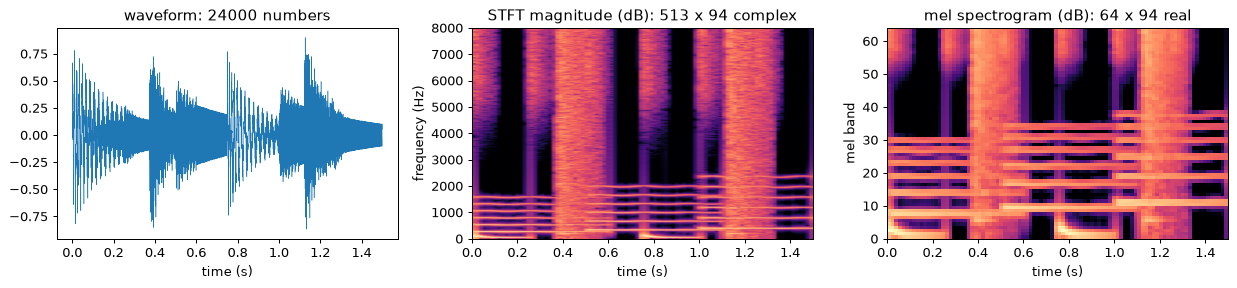

In [2]:
def stft(x, n_fft=1024, hop=256):
    w = np.hanning(n_fft + 1)[:-1]
    xp = np.pad(x, (n_fft // 2, n_fft // 2), mode="reflect")
    n = 1 + (len(xp) - n_fft) // hop
    idx = np.arange(n_fft)[None, :] + hop * np.arange(n)[:, None]
    return np.fft.rfft(xp[idx] * w, axis=1).T            # shape (frequencies, frames)

def istft(S, n_fft=1024, hop=256):
    w = np.hanning(n_fft + 1)[:-1]
    fr = np.fft.irfft(S.T, n=n_fft, axis=1) * w
    n = fr.shape[0]
    out = np.zeros(hop * (n - 1) + n_fft); ws = np.zeros_like(out)
    for i in range(n):
        out[i * hop:i * hop + n_fft] += fr[i]; ws[i * hop:i * hop + n_fft] += w ** 2
    return (out / np.maximum(ws, 1e-8))[n_fft // 2:-(n_fft // 2)]

def hz2mel(f): return 2595 * np.log10(1 + f / 700)

def mel_fb(sr, n_fft, n_mels, fmin=0.0, fmax=None):
    fmax = fmax or sr / 2
    pts = 700 * (10 ** (np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2) / 2595) - 1)
    bins = np.fft.rfftfreq(n_fft, 1 / sr)
    fb = np.zeros((n_mels, len(bins)))
    for i in range(n_mels):
        l, c, r = pts[i:i + 3]
        fb[i] = np.clip(np.minimum((bins - l) / (c - l), (r - bins) / (r - c)), 0, None)
    return fb

db = lambda S: 20 * np.log10(np.abs(S) + 1e-5)

S = stft(demo, 1024, 256)
FB64 = mel_fb(SR, 1024, 64, 0, 8000)
M = FB64 @ np.abs(S) ** 2
xr = istft(S, 1024, 256)
print("STFT shape", S.shape, "mel shape", M.shape)
print("max reconstruction error with magnitude AND phase:", float(np.abs(xr - demo[:len(xr)]).max()))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
tt = np.arange(len(demo)) / SR
ax[0].plot(tt, demo, lw=0.4); ax[0].set_title(f"waveform: {len(demo)} numbers"); ax[0].set_xlabel("time (s)")
im = ax[1].imshow(db(S), origin="lower", aspect="auto", extent=[0, 1.5, 0, 8000], vmin=-60, cmap="magma")
ax[1].set_title(f"STFT magnitude (dB): {S.shape[0]} x {S.shape[1]} complex")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("frequency (Hz)")
ax[2].imshow(10 * np.log10(M + 1e-6), origin="lower", aspect="auto", extent=[0, 1.5, 0, 64], vmin=-40, cmap="magma")
ax[2].set_title(f"mel spectrogram (dB): {M.shape[0]} x {M.shape[1]} real")
ax[2].set_xlabel("time (s)"); ax[2].set_ylabel("mel band")
plt.tight_layout(); plt.show()

The kicks are the vertical low-frequency bursts, the snares broadband bursts, the hi-hats thin bright bursts at the top, and the three notes are stacks of horizontal lines (the harmonics). The mel panel shows the same events with the high frequencies squeezed and the phase gone: 64 x 94 real numbers instead of 513 x 94 complex ones.

Now the window trade-off, measured instead of asserted. We take two steady tones 40 Hz apart (440 and 480 Hz) and an isolated click, and ask, for three window sizes: how many separate spectral peaks do we see for the two tones, and how long (in milliseconds, at half maximum) does the click appear to last?

In [3]:
t1 = np.arange(SR) / SR
two_tones = np.sin(2 * np.pi * 440 * t1) + np.sin(2 * np.pi * 480 * t1)
click = np.zeros(SR); click[SR // 2] = 1.0
rows = []
for n_fft in (128, 512, 2048):
    spec = np.abs(stft(two_tones, n_fft, n_fft // 4)).mean(1); fr = np.fft.rfftfreq(n_fft, 1 / SR)
    band = (fr > 200) & (fr < 800)
    pk, _ = sps.find_peaks(db(spec[band]), prominence=3)
    hop = n_fft // 16
    e = (np.abs(stft(click, n_fft, hop)) ** 2).sum(0)
    width_ms = (e > e.max() / 2).sum() * hop / SR * 1000
    rows.append({"window N": n_fft, "window (ms)": 1000 * n_fft / SR, "bin spacing (Hz)": SR / n_fft,
                 "peaks seen for the 2 tones": len(pk), "click looks this long (ms)": round(width_ms, 1)})
print(pd.DataFrame(rows).round(1).to_string(index=False))

 window N  window (ms)  bin spacing (Hz)  peaks seen for the 2 tones  click looks this long (ms)
      128          8.0             125.0                           1                         2.5
      512         32.0              31.2                           1                        10.0
     2048        128.0               7.8                           2                        48.0


**Reading.** The two tones are resolved as two peaks only with the long window (bin spacing 7.8 Hz, narrower than the 40 Hz gap), while the short window (125 Hz per bin) merges them into one. The click is the mirror image: it looks as long as the window itself. There is no window size that is good at both, which is why audio models pick a compromise (here 1,024 samples = 64 ms, a typical choice for speech and music) or use several resolutions at once (the loss functions of modern vocoders do).

### Neural codec tokens, measured

EnCodec ([Défossez et al., 2022](https://arxiv.org/abs/2210.13438)) is a real pre-trained neural codec. Its code is MIT licensed (repository [facebookresearch/encodec](https://github.com/facebookresearch/encodec)); the [model card of the 24 kHz checkpoint](https://huggingface.co/facebook/encodec_24khz) names no separate weights licence, so check the repository before any commercial use. It runs at 24 kHz and produces 75 frames per second. Asking for a **target bandwidth** selects how many codebooks are used (1.5 kbit/s uses 2 codebooks, 24 kbit/s uses 32; each codebook index costs 10 bits). We encode our demo clip at five bandwidths and measure two things against the original: the **log-spectral distance** (LSD, in dB, the root-mean-square difference of the log power spectra, lower is better) and the **scale-invariant signal-to-distortion ratio** (SI-SDR, in dB, higher is better; it compares waveforms sample by sample, so it also punishes phase differences the ear may not care about).

Loading weights:   0%|          | 0/252 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 252/252 [00:00<00:00, 11638.78it/s]

 kbit/s  codebooks  integers per second  compression vs 16-bit PCM  LSD (dB)  SI-SDR (dB)
    1.5          2                  150                        256      6.10         -1.0
    3.0          4                  300                        128      5.64          1.3
    6.0          8                  600                         64      5.06          3.5
   12.0         16                 1200                         32      4.64          4.6
   24.0         32                 2400                         16      4.37          5.1


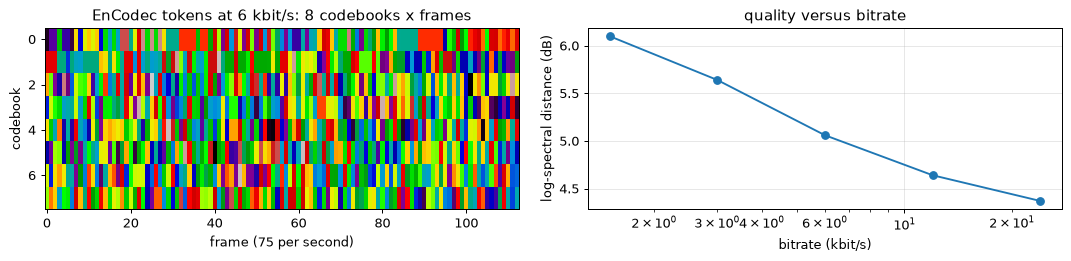

original


EnCodec 1.5 kbit/s (2 codebooks)


EnCodec 6 kbit/s (8 codebooks)


[section 2 (codec): 3 s]


In [4]:
t0 = time.time()
from transformers import EncodecModel
codec = EncodecModel.from_pretrained("facebook/encodec_24khz").eval()
x24 = sps.resample_poly(demo, 3, 2).astype(np.float32)

def lsd(x, y, n_fft=1024, hop=256):
    L = min(len(x), len(y))
    PA, PB = np.abs(stft(x[:L], n_fft, hop)) ** 2, np.abs(stft(y[:L], n_fft, hop)) ** 2
    fl = 1e-6 * PA.max()                                               # ignore everything below -60 dB of the loudest bin
    A, B = np.log10(PA + fl), np.log10(PB + fl)
    return float(np.sqrt(((10 * (A - B)) ** 2).mean(0)).mean())

def si_sdr(ref, est):
    L = min(len(ref), len(est)); ref, est = ref[:L], est[:L]
    a = (est * ref).sum() / (ref ** 2).sum()
    return float(10 * np.log10(((a * ref) ** 2).sum() / (((a * ref) - est) ** 2).sum()))

rows, dec, codes_keep = [], {}, {}
for bw in (1.5, 3.0, 6.0, 12.0, 24.0):
    with torch.no_grad():
        e = codec.encode(torch.tensor(x24)[None, None], bandwidth=bw)
        y = codec.decode(e.audio_codes, e.audio_scales).audio_values[0, 0].numpy()[:len(x24)]
    n_cb, n_fr = e.audio_codes.shape[2], e.audio_codes.shape[3]
    dec[bw], codes_keep[bw] = y, e.audio_codes[0, 0].numpy()
    rows.append({"kbit/s": bw, "codebooks": n_cb, "integers per second": n_cb * 75, "compression vs 16-bit PCM": round(24000 * 16 / (bw * 1000)),
                 "LSD (dB)": round(lsd(x24, y), 2), "SI-SDR (dB)": round(si_sdr(x24, y), 1)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].imshow(codes_keep[6.0], aspect="auto", cmap="nipy_spectral", interpolation="nearest")
ax[0].set_title("EnCodec tokens at 6 kbit/s: 8 codebooks x frames"); ax[0].set_xlabel("frame (75 per second)"); ax[0].set_ylabel("codebook")
ax[1].plot([r["kbit/s"] for r in rows], [r["LSD (dB)"] for r in rows], "o-")
ax[1].set_xscale("log"); ax[1].set_xlabel("bitrate (kbit/s)"); ax[1].set_ylabel("log-spectral distance (dB)"); ax[1].set_title("quality versus bitrate")
ax[1].grid(alpha=0.3); plt.tight_layout(); plt.show()
play(x24, 24000, "original"); play(dec[1.5], 24000, "EnCodec 1.5 kbit/s (2 codebooks)"); play(dec[6.0], 24000, "EnCodec 6 kbit/s (8 codebooks)")
lap("section 2 (codec)", t0)

**Reading.** Going from 1.5 to 24 kbit/s (256 times to 16 times smaller than the 16-bit original) lowers the log-spectral distance from 6.1 to 4.4 dB, but most of the gain comes early: 1.5 to 6 kbit/s buys 1.0 dB, 12 to 24 kbit/s only 0.3 dB. The tokens at 6 kbit/s are a grid of 8 rows by 113 columns of integers between 0 and 1,023, and the first row (the first codebook) carries the coarse structure while later rows refine it. The SI-SDR stays between -1 and 5 dB even at 24 kbit/s: a neural codec does not reproduce the waveform sample by sample, it reproduces something that sounds similar, so a waveform metric is a poor judge of it (and the reason we also report a spectral one). The floor of about 4 dB is plausible because the clip is synthetic and full of noise bursts that no codec can predict exactly, and the codec was trained on speech, music and general sound, not on our synthesiser. This is one clip: use your ears on the three players, and treat the table as an illustration, not a benchmark.

## 3. From spectrogram back to waveform: Griffin-Lim and a neural vocoder

Most generators (diffusion over spectrograms, text-to-speech acoustic models) output a **magnitude** spectrogram and no phase. Getting a waveform back needs a **vocoder**. Two ways:

* **Griffin-Lim** ([Griffin and Lim, 1984](https://doi.org/10.1109/TASSP.1984.1164317)) is an iterative algorithm without learning: start with a random phase, go to the time domain with the inverse STFT, go back with the STFT, keep the new *phase* but restore the target *magnitude*, and repeat. Each round can only lower the inconsistency between the magnitude and a real signal, but it ends in a local optimum, and the typical artefact is a metallic, "phasey" sound. A **momentum** variant (the "fast" Griffin-Lim) converges faster.
* A **neural vocoder** is a network trained to turn a mel spectrogram into a waveform. **HiFi-GAN** ([Kong et al., 2020](https://arxiv.org/abs/2010.05646)) is a convolutional generator trained adversarially with discriminators that look at the waveform at several periods and scales, so it learns to produce the phase and fine detail that make sound natural, and it is fast. We run the HiFi-GAN checkpoint released with SpeechT5 ([Ao et al., 2022](https://arxiv.org/abs/2110.07205)): [model card](https://huggingface.co/microsoft/speecht5_hifigan), **MIT licence**, 16 kHz, 80 mel bands, trained on read speech (LibriTTS), so our synthetic music is outside its training domain.

The mel spectrogram has fewer numbers than the STFT, so for the mel route we first estimate a linear-frequency magnitude with a few multiplicative non-negative least-squares updates, then run Griffin-Lim on it. We measure the **multi-resolution log-spectral distance** (mean absolute difference of natural-log magnitudes at three window sizes; lower is better), the **log-mel distance** and, to show why it is not used here, the waveform SI-SDR.

Loading weights:   0%|          | 0/158 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 158/158 [00:00<00:00, 48157.84it/s]

frames 94 samples 24064


HiFi-GAN: 1.50 s of audio in 0.16 s on the CPU (real-time factor 0.11)
                           method  multi-resolution log-spectral dist.  log-mel dist. (log10)  SI-SDR (dB)
 Griffin-Lim, full STFT magnitude                                0.042                  0.009        -23.3
Griffin-Lim, from the 80-band mel                                0.378                  0.046        -20.3
   HiFi-GAN, from the 80-band mel                                0.441                  0.184        -29.5


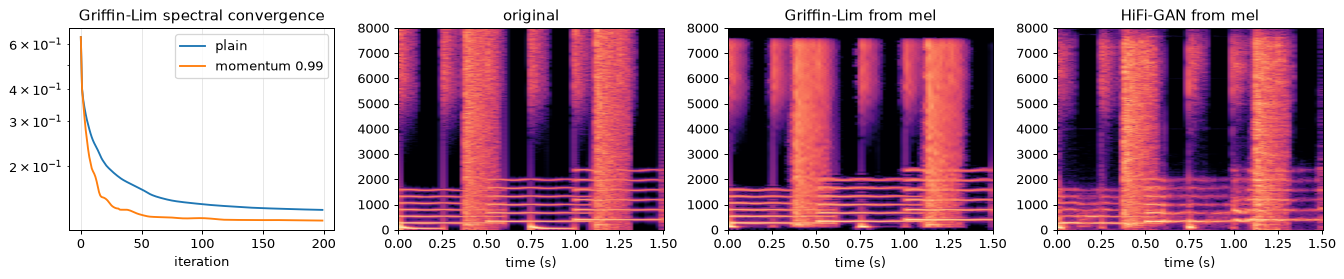

original


Griffin-Lim from the full STFT magnitude


Griffin-Lim from the mel


HiFi-GAN from the mel


[section 3 (vocoders): 2 s]


In [5]:
t0 = time.time()
def griffin_lim(S, n_iter=100, n_fft=1024, hop=256, momentum=0.0, seed=0):
    rg = np.random.default_rng(seed)
    X = S * np.exp(2j * np.pi * rg.random(S.shape)); prev = None; hist = []
    for _ in range(n_iter):
        P = stft(istft(X, n_fft, hop), n_fft, hop)
        hist.append(np.linalg.norm(np.abs(P) - S) / np.linalg.norm(S))      # spectral convergence
        Y = P if prev is None else P + momentum * (P - prev)
        prev = P
        X = S * np.exp(1j * np.angle(Y))
    return istft(X, n_fft, hop), hist

def msd(x, y, sizes=(512, 1024, 2048)):
    L = min(len(x), len(y))
    out = []
    for n in sizes:
        A, B = np.abs(stft(x[:L], n, n // 4)), np.abs(stft(y[:L], n, n // 4)); fl = 1e-3 * A.max()      # floor at -60 dB
        out.append(np.abs(np.log(A + fl) - np.log(B + fl)).mean())
    return float(np.mean(out))

from transformers import SpeechT5HifiGan, SpeechT5FeatureExtractor
fe = SpeechT5FeatureExtractor.from_pretrained("microsoft/speecht5_tts")
voc = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").eval()
FBV = fe.mel_filters                                                   # (513, 80)

def vocoder_mel(x):                                                    # log10 mel (frames, 80) as the vocoder expects
    return fe(audio_target=x, sampling_rate=16000, return_tensors="np").input_values[0]

mel_o = vocoder_mel(demo)
n_fr = mel_o.shape[0]; L = 256 * n_fr
ref = np.pad(demo, (0, max(0, L - len(demo))))[:L]; S_ref = np.abs(stft(ref, 1024, 256))[:, :n_fr + 1]
print("frames", n_fr, "samples", L)

# 1) Griffin-Lim from the full STFT magnitude, with and without momentum
_, h_plain = griffin_lim(S_ref, 200, momentum=0.0)
y_gl, h_fast = griffin_lim(S_ref, 200, momentum=0.99)
# 2) Griffin-Lim from the 80-band mel magnitude (NNLS estimate of the linear magnitude)
Mm = (10 ** mel_o).T                                                   # (80, frames), magnitude-mel
Sx = np.maximum(np.linalg.pinv(FBV.T) @ Mm, 1e-6)
for _ in range(60):
    Sx *= (FBV @ Mm) / (FBV @ (FBV.T @ Sx) + 1e-8)
y_glm, _ = griffin_lim(Sx, 100, momentum=0.99)
# 3) neural vocoder from the same mel
with torch.no_grad():
    tv = time.time(); y_hg = voc(torch.tensor(mel_o)[None]).numpy()[0]; t_voc = time.time() - tv
print(f"HiFi-GAN: {len(y_hg) / SR:.2f} s of audio in {t_voc:.2f} s on the CPU (real-time factor {t_voc / (len(y_hg) / SR):.2f})")

def logmel_dist(x):
    m = vocoder_mel(x[:L])[:n_fr]; fl = mel_o.max() - 3                  # log10 scale: ignore below -60 dB
    return float(np.abs(np.maximum(m, fl) - np.maximum(mel_o, fl)).mean())

res = []
for name, y in [("Griffin-Lim, full STFT magnitude", y_gl), ("Griffin-Lim, from the 80-band mel", y_glm), ("HiFi-GAN, from the 80-band mel", y_hg)]:
    res.append({"method": name, "multi-resolution log-spectral dist.": round(msd(ref, y), 3), "log-mel dist. (log10)": round(logmel_dist(y), 3), "SI-SDR (dB)": round(si_sdr(ref, y), 1)})
print(pd.DataFrame(res).to_string(index=False))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
ax[0].semilogy(h_plain, label="plain"); ax[0].semilogy(h_fast, label="momentum 0.99")
ax[0].set_title("Griffin-Lim spectral convergence"); ax[0].set_xlabel("iteration"); ax[0].legend(); ax[0].grid(alpha=0.3)
for a, (nm, y) in zip(ax[1:], [("original", ref), ("Griffin-Lim from mel", y_glm), ("HiFi-GAN from mel", y_hg)]):
    a.imshow(db(stft(y[:L], 1024, 256)), origin="lower", aspect="auto", extent=[0, L / SR, 0, 8000], vmin=-60, cmap="magma"); a.set_title(nm); a.set_xlabel("time (s)")
plt.tight_layout(); plt.show()
play(ref, SR, "original"); play(y_gl, SR, "Griffin-Lim from the full STFT magnitude")
play(y_glm, SR, "Griffin-Lim from the mel"); play(y_hg, SR, "HiFi-GAN from the mel")
lap("section 3 (vocoders)", t0)

**Reading.** Three things. First, Griffin-Lim given the *full* STFT magnitude recovers the sound almost perfectly in magnitude (distance 0.04) and yet its SI-SDR is -23 dB: the phase it found is completely different from the original one, and the waveform error says nothing about how it sounds. Second, from the 80-band mel, Griffin-Lim scored better than HiFi-GAN on our spectral measures (0.38 versus 0.44, and 0.05 versus 0.18 on the log-mel distance). That is **not** evidence that Griffin-Lim sounds better: these measures compare magnitudes, which is exactly what Griffin-Lim optimises, while HiFi-GAN was trained to fool discriminators with natural-sounding waveforms, on read speech, and our input is synthetic music outside that domain. Third, speed: HiFi-GAN made 1.5 s of audio in 0.16 s (a real-time factor of 0.11) with a single forward pass, while Griffin-Lim needs many iterations of two transforms. Compare the four players by ear before believing any of the numbers; one clip and one input is a demonstration, not a ranking.

## 4. Two families of audio generators on a toy sound set

There are two dominant ways to generate audio from a representation, both used by the systems of section 5:

* **Autoregressive over discrete tokens.** Turn the sound into integers (codec tokens), train a language model to predict the next integer given the past and a **condition** (a class or a text prompt), sample token by token, decode. It inherits everything from language models (scaling, prompting, sampling temperature) and the quality ceiling is set by the codec.
* **Diffusion over spectrograms or latents.** Treat the mel spectrogram as an image, train a denoiser exactly as in [module 05 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/05-diffusion-models/), sample by iterative denoising, and then invert it with a vocoder. Diffusion directly on waveforms also exists: **DiffWave** ([Kong et al., 2021](https://arxiv.org/abs/2009.09761)) is a vocoder of this kind, and Stable Audio ([Evans et al., 2024](https://arxiv.org/abs/2402.04825)) runs diffusion in the latent space of a learned audio autoencoder.

### The toy sound set

Five sound types, 0.512 s each at 16 kHz, with random pitch, decay, onset time and noise level: **kick**, **snare**, **hat**, a steady **tone** and an upward **chirp**. We represent each as a 32 x 32 log-mel image (32 mel bands by 32 frames, window 512, hop 256), scaled to [-1, 1]. 1,300 clips train the generators, 300 held-out clips are the reference for measurement and 300 more real clips measure the floor.

### How we measure generated sounds (the idea behind real evaluation)

We train a small convolutional **judge** on the real training sounds to tell the five types apart. Then, for a generated set, we report: (1) **type accuracy**: the judge's agreement with the type the generator was asked for; (2) a **Fréchet distance** (FD) between the judge's 32-dimensional feature vectors of generated and real held-out sounds: fit a Gaussian with mean $\mu$ and covariance $\Sigma$ to each set and compute $\lVert\mu_g-\mu_r\rVert^2+\mathrm{tr}\big(\Sigma_g+\Sigma_r-2(\Sigma_g\Sigma_r)^{1/2}\big)$, where $g$ means generated and $r$ means real (lower is better; this is the recipe of the Fréchet audio distance, see section 6); (3) a **spectral nearest-neighbour distance**: the average root-mean-square distance, in the scaled log-mel image, from each generated sound to its closest *training* sound (very small would mean copying the training set, large means off-distribution). The first line of each table gives the same measures for a second, separate set of real sounds, as a floor (a real set is not at distance 0 from another real set: the Fréchet distance of two finite samples is always above 0).

train (1300, 32, 32) reference test (300, 32, 32) second real set (300, 32, 32)


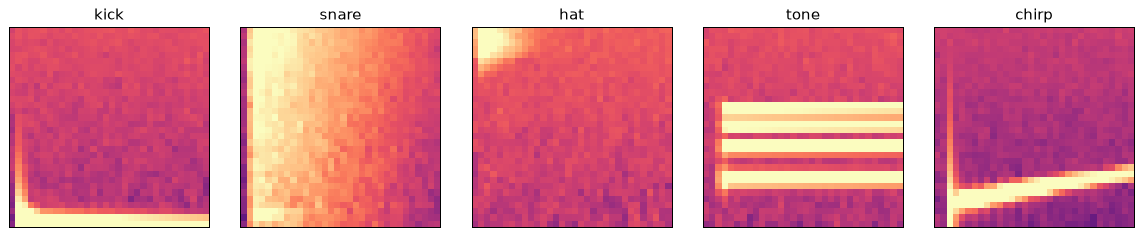

judge accuracy on real held-out sounds: 1.0
                                set  type accuracy  Frechet distance  nearest-train distance
a second set of real sounds (floor)            1.0             61.58                   0.101
[section 4 data and judge: 3 s]


In [6]:
t0 = time.time()
rng = np.random.default_rng(1)
NS, NF, NM, CLASSES = 8192, 32, 32, ["kick", "snare", "hat", "tone", "chirp"]
FBT = mel_fb(SR, 512, NM, 0, 8000)

def make_clip(c, rg):
    onset = int(rg.integers(0, 700)); n = NS - onset
    if c == 0:   y = kick(n, rg.uniform(100, 160), rg.uniform(40, 60), rg.uniform(0.08, 0.2))
    elif c == 1: y = snare(n, rg, rg.uniform(150, 260), rg.uniform(0.06, 0.14), rg.uniform(0.5, 1.0))
    elif c == 2: y = hat(n, rg, rg.uniform(0.02, 0.06))
    elif c == 3: y = harmonic(rg.uniform(200, 900), n / SR, n_harm=int(rg.integers(2, 6)), tau=rg.uniform(0.2, 0.6))
    else:
        f_a = rg.uniform(250, 600); y = chirp(n, f_a, f_a * rg.uniform(2.5, 4.5), rg.uniform(0.15, 0.4))
    x = np.zeros(NS); y = y[:n]; x[onset:onset + len(y)] = y
    x = x / (np.abs(x).max() + 1e-9) + rg.standard_normal(NS) * rg.uniform(0.0005, 0.01)
    return x

def logmel_img(x):
    P = np.abs(stft(x, 512, 256))[:, :NF] ** 2
    return np.log10(FBT @ P + 1e-6)                                     # (NM, NF)

per_class = 380
raw, labels = [], []
for c in range(5):
    for _ in range(per_class):
        raw.append(make_clip(c, rng)); labels.append(c)
raw = np.array(raw, dtype=np.float32); labels = np.array(labels)
L_img = np.array([logmel_img(x) for x in raw])
LO, HI = -6.0, 2.0
Xn = (np.clip(L_img, LO, HI) - LO) / (HI - LO) * 2 - 1                  # scaled to [-1, 1]
perm = rng.permutation(len(Xn))
test_idx = np.concatenate([perm[labels[perm] == c][:60] for c in range(5)])            # the reference set for every measurement
test2_idx = np.concatenate([perm[labels[perm] == c][60:120] for c in range(5)])        # a second real set, to measure the floor
mask = np.ones(len(Xn), bool); mask[test_idx] = False; mask[test2_idx] = False
Xtr, ytr, Xte, yte, Xte2, yte2 = Xn[mask], labels[mask], Xn[test_idx], labels[test_idx], Xn[test2_idx], labels[test2_idx]
print("train", Xtr.shape, "reference test", Xte.shape, "second real set", Xte2.shape)

fig, ax = plt.subplots(1, 5, figsize=(13, 2.6))
for c in range(5):
    ax[c].imshow(Xtr[ytr == c][0], origin="lower", cmap="magma", vmin=-1, vmax=1); ax[c].set_title(CLASSES[c]); ax[c].set_xticks([]); ax[c].set_yticks([])
plt.tight_layout(); plt.show()

class Judge(nn.Module):
    def __init__(s):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(512, 32), nn.ReLU())
        s.head = nn.Linear(32, 5)
    def feats(s, x): return s.conv(x)
    def forward(s, x): return s.head(s.conv(x))

torch.manual_seed(0)
judge = Judge(); opt = torch.optim.Adam(judge.parameters(), 2e-3)
Xt_, yt_ = torch.tensor(Xtr)[:, None].float(), torch.tensor(ytr.astype(np.int64))
for ep in range(12):
    p = torch.randperm(len(Xt_))
    for i in range(0, len(p), 64):
        b = p[i:i + 64]; loss = F.cross_entropy(judge(Xt_[b]), yt_[b]); opt.zero_grad(); loss.backward(); opt.step()
judge.eval()

@torch.no_grad()
def judge_feats(X):
    Xt = torch.tensor(np.asarray(X))[:, None].float()
    return judge.feats(Xt).numpy(), judge(Xt).argmax(1).numpy()

def frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0); s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    tr = np.sqrt(np.clip(np.linalg.eigvals(s1 @ s2).real, 0, None)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr)

F_te, pred_te = judge_feats(Xte)
Xtr_flat = torch.tensor(Xtr.reshape(len(Xtr), -1)).float()
def nn_dist(X):
    d = torch.cdist(torch.tensor(np.asarray(X).reshape(len(X), -1)).float(), Xtr_flat) / math.sqrt(NM * NF)
    return float(d.min(1).values.mean())

def score(name, X, asked):
    Fg, pg = judge_feats(X)
    return {"set": name, "type accuracy": round(float((pg == asked).mean()), 3), "Frechet distance": round(frechet(Fg, F_te), 2), "nearest-train distance": round(nn_dist(X), 3)}

print("judge accuracy on real held-out sounds:", round(float((pred_te == yte).mean()), 3))
sub2 = np.concatenate([np.where(yte2 == c)[0][:30] for c in range(5)]); sub1 = np.concatenate([np.where(yte == c)[0][:30] for c in range(5)])
score_rows = [score("a second set of real sounds (floor)", Xte2[sub2], yte2[sub2])]
print(pd.DataFrame(score_rows).to_string(index=False))
lap("section 4 data and judge", t0)

### Family 1: a one-codebook codec and an autoregressive model over its tokens

We build the smallest possible codec: **vector quantisation** by k-means. Every column of the image (one 32-band spectrum, i.e. one time frame) is replaced by the index of the closest of $K = 64$ centroids learned on the training frames. A sound becomes **32 integers**. An autoregressive model, a two-layer **GRU** (gated recurrent unit, see [module 06 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/06-recurrent-networks/)), is trained to predict the next token given the previous ones and a **class token** put at the start (the "prompt"), exactly like a language model. Sampling draws one token at a time from the predicted distribution. A real codec adds more codebooks (residual quantisation) and a learned encoder and decoder; the k-means codec is the one-codebook, no-learning version. Its **ceiling** is measured by quantising and dequantising *real* sounds.

In [7]:
t0 = time.time()
from sklearn.cluster import KMeans
K = 64
frames_tr = Xtr.transpose(0, 2, 1).reshape(-1, NM)                       # every time frame is one vector
km = KMeans(K, n_init=3, random_state=0).fit(frames_tr)
def tokenise(X): return km.predict(X.transpose(0, 2, 1).reshape(-1, NM)).reshape(len(X), NF)
def detokenise(tok): return km.cluster_centers_[tok].reshape(len(tok), NF, NM).transpose(0, 2, 1)
tok_tr = tokenise(Xtr)
score_rows.append(score("real held-out through the k-means codec (AR ceiling)", detokenise(tokenise(Xte[sub1])), yte[sub1]))

class ARGRU(nn.Module):
    def __init__(s, K, C=5, h=192):
        super().__init__()
        s.emb = nn.Embedding(K + C, h); s.gru = nn.GRU(h, h, 2, batch_first=True); s.out = nn.Linear(h, K)
    def forward(s, x, h=None):
        o, h = s.gru(s.emb(x), h); return s.out(o), h

torch.manual_seed(0)
ar = ARGRU(K); opt = torch.optim.Adam(ar.parameters(), 3e-3)
inp = torch.tensor(np.concatenate([K + ytr[:, None], tok_tr[:, :-1]], 1).astype(np.int64)); tgt = torch.tensor(tok_tr.astype(np.int64))
ar_loss = []
for ep in range(25):
    p = torch.randperm(len(inp))
    for i in range(0, len(p), 64):
        b = p[i:i + 64]; lo, _ = ar(inp[b]); loss = F.cross_entropy(lo.reshape(-1, K), tgt[b].reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
    ar_loss.append(loss.item())
print(f"AR GRU: final training loss {ar_loss[-1]:.3f} nats per token (uniform guess would be {math.log(K):.2f})")

@torch.no_grad()
def ar_sample(classes, temp=1.0, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.tensor((K + np.asarray(classes)).astype(np.int64))[:, None]; h = None; out = []
    for _ in range(NF):
        lo, h = ar(x, h); pr = F.softmax(lo[:, -1] / temp, -1); x = torch.multinomial(pr, 1, generator=g); out.append(x)
    return torch.cat(out, 1).numpy()

asked = np.repeat(np.arange(5), 30)
X_ar = detokenise(ar_sample(asked))
score_rows.append(score("autoregressive over tokens (GRU, T=1)", X_ar, asked))
print(pd.DataFrame(score_rows).to_string(index=False))
lap("section 4 AR", t0)

AR GRU: final training loss 0.337 nats per token (uniform guess would be 4.16)
                                                 set  type accuracy  Frechet distance  nearest-train distance
                 a second set of real sounds (floor)          1.000             61.58                   0.101
real held-out through the k-means codec (AR ceiling)          1.000            112.18                   0.099
               autoregressive over tokens (GRU, T=1)          0.993            287.99                   0.098
[section 4 AR: 29 s]


### Family 2: a small diffusion model over the mel image

We reuse the denoising recipe of module 05: noise the image over $T = 100$ steps with the schedule $\beta_t$ (noise added at step $t$), train a small U-Net (a convolutional network that goes down to a coarser resolution and back up with a skip connection) to predict the noise $\epsilon$ that was added, conditioned on the diffusion step and on the sound type, and sample by running the chain backwards from pure noise. The condition is dropped 10 % of the time during training so that the same network also learns the unconditional case, which allows **classifier-free guidance**: at sampling time the noise prediction is $(1+w)\,\epsilon_{\text{cond}} - w\,\epsilon_{\text{uncond}}$ with guidance weight $w$, which pushes the sample toward what is specific to the requested type. We report $w = 0$ and $w = 3$. The network is tiny (16 channels, 75,000 parameters) so that it trains in a minute or two on the CPU.

U-Net parameters: 75569


  (100 steps took 4 s)


diffusion training: loss 0.663 -> 0.062 in 83 s


sampling 150 sounds with 100 steps took 6 s


                                                  set  type accuracy  Frechet distance  nearest-train distance
                  a second set of real sounds (floor)          1.000             61.58                   0.101
 real held-out through the k-means codec (AR ceiling)          1.000            112.18                   0.099
                autoregressive over tokens (GRU, T=1)          0.993            287.99                   0.098
diffusion over the mel image (100 steps, no guidance)          0.860           7702.44                   0.152
       diffusion with classifier-free guidance, w = 3          0.987            639.55                   0.197


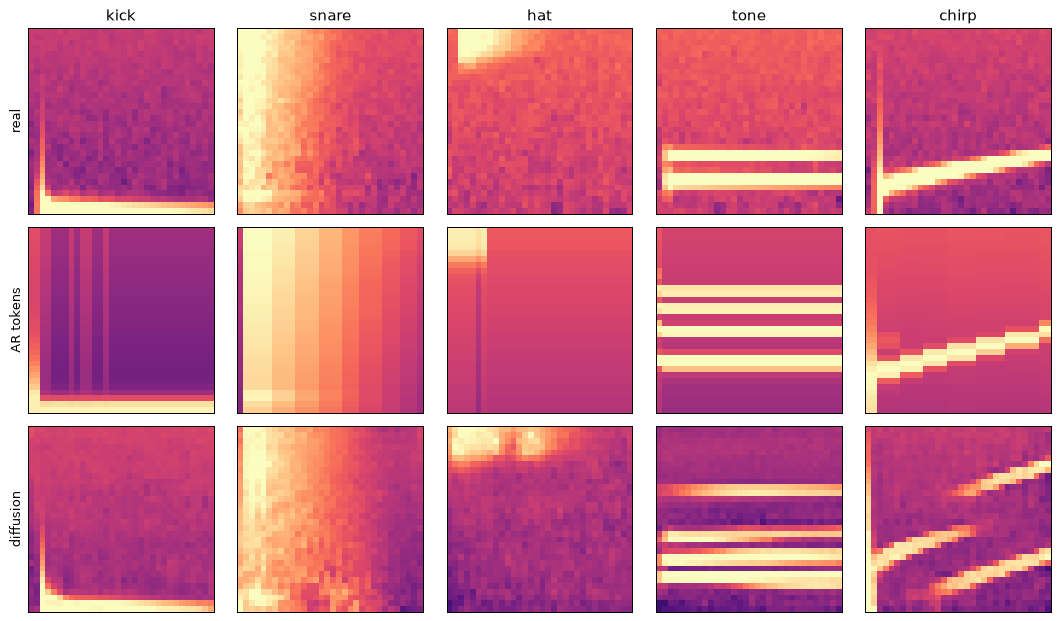

[section 4 diffusion: 102 s]


In [8]:
t0 = time.time()
TD = 100
betas = torch.linspace(1e-4, 0.04, TD); alphas = 1 - betas; abar = torch.cumprod(alphas, 0)

def temb(t, dim=32):
    f = torch.exp(-math.log(10000) * torch.arange(dim // 2) / (dim // 2)); a = t[:, None].float() * f[None]
    return torch.cat([a.sin(), a.cos()], 1)

class Blk(nn.Module):
    def __init__(s, ci, co, ed=64):
        super().__init__()
        s.c1 = nn.Conv2d(ci, co, 3, padding=1); s.c2 = nn.Conv2d(co, co, 3, padding=1)
        s.n1 = nn.GroupNorm(4, ci); s.n2 = nn.GroupNorm(4, co); s.e = nn.Linear(ed, co)
        s.sk = nn.Conv2d(ci, co, 1) if ci != co else nn.Identity()
    def forward(s, x, e):
        h = s.c1(F.silu(s.n1(x))) + s.e(e)[:, :, None, None]
        return s.sk(x) + s.c2(F.silu(s.n2(h)))

class TinyUNet(nn.Module):
    def __init__(s, ch=16, ncls=6):                                          # class 5 means 'no condition'
        super().__init__()
        s.t = nn.Sequential(nn.Linear(32, 64), nn.SiLU(), nn.Linear(64, 64)); s.cls = nn.Embedding(ncls, 64)
        s.inp = nn.Conv2d(1, ch, 3, padding=1); s.d1 = Blk(ch, ch); s.down = nn.Conv2d(ch, 2 * ch, 3, stride=2, padding=1)
        s.d2 = Blk(2 * ch, 2 * ch); s.mid = Blk(2 * ch, 2 * ch); s.up = nn.ConvTranspose2d(2 * ch, ch, 4, stride=2, padding=1)
        s.u1 = Blk(2 * ch, ch); s.out = nn.Conv2d(ch, 1, 3, padding=1)
    def forward(s, x, t, c):
        e = s.t(temb(t)) + s.cls(c)
        h0 = s.d1(s.inp(x), e); h = s.d2(s.down(h0), e); h = s.mid(h, e)
        return s.out(s.u1(torch.cat([s.up(h), h0], 1), e))

torch.manual_seed(0)
unet = TinyUNet(); print("U-Net parameters:", sum(p.numel() for p in unet.parameters()))
opt = torch.optim.Adam(unet.parameters(), 2e-3)
x0_all = torch.tensor(Xtr)[:, None].float(); c_all = torch.tensor(ytr.astype(np.int64))
STEPS_A, BS = 2000, 48
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=STEPS_A, pct_start=0.05)
dl = []
tt0 = time.time()
for step in range(STEPS_A):
    b = torch.randint(0, len(x0_all), (BS,)); x0 = x0_all[b]; t = torch.randint(0, TD, (BS,)); eps = torch.randn_like(x0)
    xt = abar[t].sqrt()[:, None, None, None] * x0 + (1 - abar[t]).sqrt()[:, None, None, None] * eps
    cc = c_all[b].clone(); cc[torch.rand(BS) < 0.1] = 5                    # 10 % of the time drop the condition
    loss = F.mse_loss(unet(xt, t, cc), eps); opt.zero_grad(); loss.backward(); opt.step(); sched.step(); dl.append(loss.item())
    if step == 99: print(f"  (100 steps took {time.time() - tt0:.0f} s)")
print(f"diffusion training: loss {np.mean(dl[:50]):.3f} -> {np.mean(dl[-50:]):.3f} in {time.time() - tt0:.0f} s")

@torch.no_grad()
def ddpm_sample(model, classes, w=0.0, seed=0, shape=(1, NM, NF)):
    g = torch.Generator().manual_seed(seed); c = torch.tensor(np.asarray(classes).astype(np.int64)); x = torch.randn((len(c),) + shape, generator=g)
    for i in reversed(range(TD)):
        t = torch.full((len(c),), i); eps = model(x, t, c)
        if w > 0: eps = (1 + w) * eps - w * model(x, t, torch.full_like(c, 5))      # classifier-free guidance
        x0 = (x - (1 - abar[i]).sqrt() * eps) / abar[i].sqrt()
        ab_prev = abar[i - 1] if i > 0 else torch.tensor(1.0)
        mean = (ab_prev.sqrt() * betas[i] / (1 - abar[i])) * x0 + (alphas[i].sqrt() * (1 - ab_prev) / (1 - abar[i])) * x
        x = mean + ((1 - ab_prev) / (1 - abar[i]) * betas[i]).sqrt() * torch.randn(x.shape, generator=g) if i > 0 else mean
    return x[:, 0].numpy()

ts = time.time(); X_df0 = ddpm_sample(unet, asked); print(f"sampling {len(asked)} sounds with {TD} steps took {time.time() - ts:.0f} s")
X_df = ddpm_sample(unet, asked, w=3.0)
score_rows.append(score("diffusion over the mel image (100 steps, no guidance)", X_df0, asked))
score_rows.append(score("diffusion with classifier-free guidance, w = 3", X_df, asked))
print(pd.DataFrame(score_rows).to_string(index=False))

fig, ax = plt.subplots(3, 5, figsize=(12, 7))
for c in range(5):
    for r, (nm, X) in enumerate([("real", Xte[yte == c]), ("AR tokens", X_ar[asked == c]), ("diffusion", X_df[asked == c])]):
        ax[r, c].imshow(X[1], origin="lower", cmap="magma", vmin=-1, vmax=1); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        if c == 0: ax[r, c].set_ylabel(nm)
        if r == 0: ax[r, c].set_title(CLASSES[c])
plt.tight_layout(); plt.show()
lap("section 4 diffusion", t0)

**Reading.** The measurements, on 150 generated sounds per row (30 per type) and one training run per model, are in the table above. The floor is a second set of real sounds: its Fréchet distance is 62, so a distance of that size means "indistinguishable from real" at this sample size. Reading it row by row:

* **Autoregressive over tokens**: the judge recognises 99.3 % of the sounds as the requested type (one error in 150) and the Fréchet distance is 288, against 112 for *real* sounds passed through the same k-means codec. The codec is the main limit: the model samples 32 tokens well, but a table of 64 spectra cannot represent everything.
* **Diffusion without guidance**: only 86 % of the sounds are recognised and the Fréchet distance is 7,702: the sounds have the right shapes (the drum decays, the chirp sweeps) but the structure is weak and the overall level is off (in a side check made while building the notebook, the generated images were darker than real ones), and the judge's features react strongly to that.
* **Diffusion with classifier-free guidance** ($w = 3$): 98.7 % recognised and a distance of 640, twelve times lower, from the same trained network. Guidance trades diversity for fidelity: the nearest-training-sound distance rises from 0.15 to 0.20 (twice the floor of 0.10), which suggests exaggerated, less natural examples, not copies.

What we can **not** conclude: that one family is better. The 0.993 versus 0.987 accuracy is a difference of one sound; the Fréchet distances depend on a 32-feature judge trained by us and on the sample size (section 6); the diffusion network has 75,000 parameters and 2,000 training steps; and each number is a single seed. What the experiment does show is the characteristic trade-offs: the token model is limited by its codec and trivially fast to sample (milliseconds per sound), the diffusion model needs a hundred network evaluations per sample and guidance to be usable, and a metric such as accuracy can look fine while a distribution distance is far from the floor.

### Hearing the toy samples

To listen, we turn a generated log-mel image back into a waveform: undo the scaling, go from the 32 mel bands to a linear magnitude with the same non-negative least-squares step as before, and run Griffin-Lim. The sounds are short (0.5 s) and the conversion is crude, so expect a rough character, not a clean one; the point is that the *type* of sound is recognisable.

In [9]:
def image_to_audio(img, n_iter=60):
    P = 10 ** ((np.asarray(img) + 1) / 2 * (HI - LO) + LO)                 # power mel
    Mg = np.sqrt(np.maximum(P - 1e-6, 1e-9))                                # rough magnitude-mel
    Sx = np.maximum(np.linalg.pinv(FBT) @ Mg, 1e-6)
    for _ in range(40):
        Sx *= (FBT.T @ Mg) / (FBT.T @ (FBT @ Sx) + 1e-8)
    y, _ = griffin_lim(Sx, n_iter, n_fft=512, hop=256, momentum=0.99)
    return y

for c in (0, 2, 3):
    play(image_to_audio(Xte[yte == c][1]), SR, f"{CLASSES[c]}: real")
    play(image_to_audio(X_ar[asked == c][1]), SR, f"{CLASSES[c]}: autoregressive over tokens")
    play(image_to_audio(X_df[asked == c][1]), SR, f"{CLASSES[c]}: diffusion")

kick: real


kick: autoregressive over tokens


kick: diffusion


hat: real


hat: autoregressive over tokens


hat: diffusion


tone: real


tone: autoregressive over tokens


tone: diffusion


## 5. A real text-to-music model: MusicGen small

MusicGen ([Copet et al., 2023](https://arxiv.org/abs/2306.05284)) is family 1 at scale: an autoregressive Transformer over the tokens of an EnCodec-style codec (32 kHz, four codebooks at 50 frames per second), conditioned on a text prompt encoded by a frozen T5 text encoder. Its key trick is a **delay pattern**: the four codebooks of one frame are not predicted one after the other (which would multiply the sequence length by four) but in parallel, with codebook $k$ shifted by $k$ steps, so one Transformer step produces one token for every codebook. We run the 300-million-parameter **small** checkpoint ([model card](https://huggingface.co/facebook/musicgen-small), code in [audiocraft](https://github.com/facebookresearch/audiocraft)).

**Licence, stated carefully:** the code is MIT licensed, but the **model weights are released under CC-BY-NC 4.0, non-commercial**. Running it in a course notebook is fine; shipping its output in a commercial product is not allowed with these weights. The model was trained on licensed music (a company's sound collection and two stock-music catalogues, per the model card), which is the reason for the restriction. The music is generated from text prompts: nobody is copied on purpose, but the model card also lists limits (it does not generate vocals, and it does worse on non-Western styles).

We generate four seconds for three prompts, with sampling and classifier-free guidance of 3, and compute crude descriptors (spectral centroid, a measure of brightness, and the rate of onsets, found as peaks of the spectral flux) to check that the prompts are not ignored. Each clip costs several seconds on the CPU.

Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 611/611 [00:00<00:00, 9716.14it/s]

MusicGen small parameters (millions): 587


3.9 s of audio per prompt at 32000 Hz; tokens: 200 steps x 4 codebooks = 800 integers; generation times (s): [10.7, 10.5, 10.4]
                                             prompt  spectral centroid (Hz)  onsets per second
                 slow lullaby played on a music box                    2220                2.0
energetic drum and bass beat with a heavy kick drum                    5954                6.3
                   solo acoustic guitar folk melody                    1101                4.3


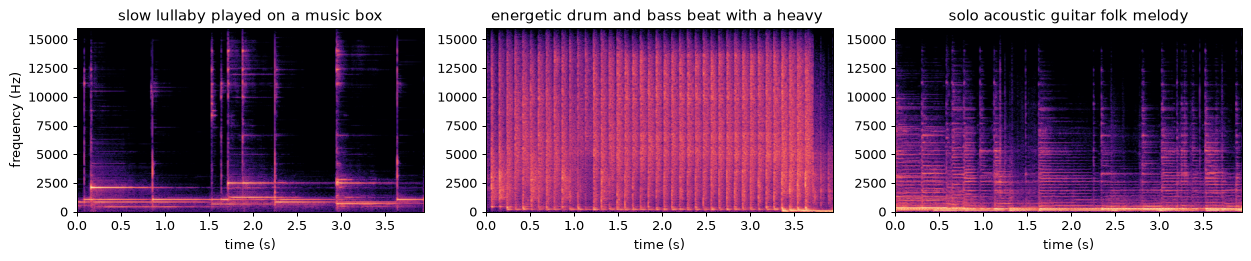

MusicGen small: slow lullaby played on a music box


MusicGen small: energetic drum and bass beat with a heavy kick drum


MusicGen small: solo acoustic guitar folk melody


[section 5 (MusicGen): 33 s]


In [10]:
t0 = time.time()
from transformers import AutoProcessor, MusicgenForConditionalGeneration
proc = AutoProcessor.from_pretrained("facebook/musicgen-small")
mg = MusicgenForConditionalGeneration.from_pretrained("facebook/musicgen-small").eval()
print("MusicGen small parameters (millions):", round(sum(p.numel() for p in mg.parameters()) / 1e6))
SRM = mg.config.audio_encoder.sampling_rate
prompts = ["slow lullaby played on a music box", "energetic drum and bass beat with a heavy kick drum", "solo acoustic guitar folk melody"]
clips, times = [], []
for i, pr in enumerate(prompts):
    torch.manual_seed(i)
    ts = time.time()
    with torch.no_grad():
        a = mg.generate(**proc(text=[pr], padding=True, return_tensors="pt"), do_sample=True, guidance_scale=3.0, max_new_tokens=200)
    times.append(time.time() - ts); clips.append(a[0, 0].numpy())
sec = len(clips[0]) / SRM
print(f"{sec:.1f} s of audio per prompt at {SRM} Hz; tokens: 200 steps x 4 codebooks = 800 integers; generation times (s): {[round(x, 1) for x in times]}")

def describe(x, sr):
    S = np.abs(stft(x, 1024, 512)); fr = np.fft.rfftfreq(1024, 1 / sr)
    centroid = float((S * fr[:, None]).sum(0).mean() / (S.sum(0).mean() + 1e-9))
    flux = np.maximum(np.diff(np.log(FBM @ S + 1e-4), axis=1), 0).sum(0)
    pk, _ = sps.find_peaks(flux, height=flux.mean() + flux.std(), distance=int(0.1 * sr / 512))
    return centroid, len(pk) / (len(x) / sr)
FBM = mel_fb(SRM, 1024, 40)
rows = []
for pr, x in zip(prompts, clips):
    c, o = describe(x, SRM); rows.append({"prompt": pr, "spectral centroid (Hz)": round(c), "onsets per second": round(o, 1)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, pr, x in zip(ax, prompts, clips):
    a.imshow(db(stft(x, 1024, 256)), origin="lower", aspect="auto", extent=[0, len(x) / SRM, 0, SRM / 2], vmin=-50, cmap="magma"); a.set_title(pr[:42]); a.set_xlabel("time (s)")
ax[0].set_ylabel("frequency (Hz)"); plt.tight_layout(); plt.show()
clips16 = [sps.resample_poly(x, 1, 2).astype(np.float32) for x in clips]
for pr, x in zip(prompts, clips16):
    play(x, 16000, "MusicGen small: " + pr)
lap("section 5 (MusicGen)", t0)

**Reading.** Generating 3.9 s of music takes about 10 s on 2 CPU threads (slower than real time), with 800 integers to predict. The crude descriptors move in the expected direction: the drum-and-bass clip is the brightest (spectral centroid 5,954 Hz) and has the most onsets (6.3 per second), the guitar clip the darkest (1,101 Hz), and the music-box lullaby has the fewest onsets (2.0 per second). With one sample per prompt and two crude descriptors this is weak evidence that the prompts are used, not a measurement of quality. Listen: a model of 300 million parameters trained on licensed music produces plausible short fragments, but four seconds hide everything that is hard (a coherent structure over minutes, repeating motifs, vocals, which this model does not generate). The non-commercial weights licence is part of the result: it decides whether you can use the output.

## 6. Evaluating generated audio

Evaluating a generator is as hard as building it, because there is no single right answer to compare with. The usual toolbox, in order of cost:

* **Reference-free statistics of the output.** Loudness, clipping, silence, spectral centroid, onset rate (as above). Cheap, catch gross failures, say nothing about quality.
* **Distance between distributions: Fréchet audio distance (FAD)** ([Kilgour et al., 2019](https://arxiv.org/abs/1812.08466)). Embed a set of real clips and a set of generated clips with a pre-trained audio network (the original used VGGish, an audio classifier), fit a Gaussian to each set, and compute the Fréchet distance of section 4. Lower means the generated set looks more like the real set *in the eyes of that network*. It is the audio sibling of the FID (Fréchet inception distance) used for images. Its weaknesses are well known: it depends on the embedding network (a different network ranks systems differently), it needs many clips (the estimate is biased upwards for small sets), and it does not see what the embedding ignores.
* **Text-audio agreement.** For text-to-audio, a joint text-audio embedding (a CLAP model, the audio cousin of CLIP, see [module 04 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/04-autoencoders-gans-and-self-supervised/)) scores how well the clip matches the prompt.
* **Listening tests.** The reference method: ask people to rate clips (for example 1 to 5 mean opinion score) or to choose between two systems. Needs enough listeners and clips, blinded and randomised order, and a hidden reference and a low-quality anchor to detect careless raters; report confidence intervals. Slow and costly, and the only one that measures what we care about.

Below, with our toy judge, we check two properties of the Fréchet recipe that matter in practice: how it behaves for **small sample sizes** (comparing two sets of *real* sounds, so the true distance is zero) and whether it **grows when the sounds are degraded** in a known way.

In [11]:
t0 = time.time()
rg = np.random.default_rng(0)
F_tr_all, _ = judge_feats(Xte2)                                  # real sounds the judge never saw
rows = []
for n in (20, 50, 100, 200, 300):
    ds = [frechet(F_tr_all[rg.choice(len(F_tr_all), n, replace=False)], F_te) for _ in range(5)]
    rows.append({"clips per set": n, "FD between two sets of REAL sounds (mean of 5 draws)": round(float(np.mean(ds)), 2), "std": round(float(np.std(ds)), 2)})
print(pd.DataFrame(rows).to_string(index=False))

rows = []
for sig in (0.0, 0.1, 0.2, 0.4, 0.8):
    Xd = np.clip(Xte + rg.standard_normal(Xte.shape) * sig, -1, 1)
    Fd, pd_ = judge_feats(Xd); rows.append({"noise added to the test images": sig, "FD to clean test set": round(frechet(Fd, F_te), 2), "type accuracy": round(float((pd_ == yte).mean()), 3)})
for k in (1, 3):
    Xb = np.stack([sps.convolve2d(x, np.ones((k + 1, k + 1)) / (k + 1) ** 2, mode="same", boundary="symm") for x in Xte])
    Fd, pd_ = judge_feats(Xb); rows.append({"noise added to the test images": f"blur {k + 1}x{k + 1}", "FD to clean test set": round(frechet(Fd, F_te), 2), "type accuracy": round(float((pd_ == yte).mean()), 3)})
print(pd.DataFrame(rows).to_string(index=False))
lap("section 6", t0)

 clips per set  FD between two sets of REAL sounds (mean of 5 draws)    std
            20                                                851.73 474.42
            50                                                236.11 110.43
           100                                                105.48  27.99
           200                                                 53.30  24.43
           300                                                 17.17   0.00


noise added to the test images  FD to clean test set  type accuracy
                           0.0                  0.00          1.000
                           0.1                 58.99          1.000
                           0.2                502.48          1.000
                           0.4               3423.27          0.890
                           0.8              12515.64          0.507
                      blur 2x2                150.69          1.000
                      blur 4x4                838.53          1.000
[section 6: 0 s]


**Reading.** The Fréchet distance between two sets of *real* sounds, which should be zero, is 852 with 20 clips per set, 236 with 50, 105 with 100, 53 with 200 and 17 with all 300 (the last has no spread because it uses every clip), and the spread between random draws is of the same order as the value for small sets. So a Fréchet distance is only comparable between systems evaluated with the same embedding network **and the same number of clips**, and small evaluation sets are mostly noise. The degradation test shows the other side: added noise of 0.1 already moves the distance from 0 to 59 while the judge's accuracy stays at 100 %, and it only drops at noise 0.4 (89 %) and 0.8 (51 %); a 2x2 blur gives 151 and no accuracy loss at all. A distribution distance sees changes that a classifier's accuracy misses, in a space that is only as meaningful as the network that defines it (our judge knows five sound types and nothing about music, which is the same reason VGGish-based FAD can disagree with listeners). Report the metric together with the embedding, the sample size and, whenever possible, a listening test.

## 7. Video is frames plus time

A video is a tensor with a time axis: **frames x height x width x channels**. Three things make it harder than an image:

1. **Size.** One second of 720p video at 24 frames per second is 24 images of 0.9 million pixels each. Generating pixels directly is out of reach, so video models work in a compressed **latent** space made by an autoencoder that compresses both space and time (as the codec does for audio).
2. **Temporal consistency.** Every frame must look right *and* the frames must agree: objects keep their shape, identity and colour, and move along plausible paths. The failures are visible: flicker, objects that melt, appear or vanish, backgrounds that crawl. A model that denoises every frame independently produces exactly this.
3. **Long-range structure.** A shot is a story: cause and effect, physics, objects that leave and come back.

Architecturally there are three ways to let information flow through time:

* **Temporal convolutions.** Extend a 2D convolution to 3D, with a kernel of size 3 in time, height and width ([Tran et al., 2018](https://arxiv.org/abs/1711.11248)). The **(2+1)D** version factorises it into a 2D spatial convolution followed by a 1D temporal one: fewer weights, more non-linearities, easier to optimise. We use it below. The cost is local: to relate frames that are 100 frames apart you stack many layers.
* **Attention over time.** Alternate spatial attention (tokens of one frame attend to each other) with temporal attention (each spatial position attends to itself across frames). This is the factorisation used by the first large video diffusion models ([Ho et al., 2022](https://arxiv.org/abs/2204.03458)).
* **Attention over space-time patches.** Cut the (latent) video into small 3D patches, flatten them into one long sequence of tokens and let a Transformer attend over *all* of them (full space-time attention). It is the most flexible and the most expensive, and it is the design of Sora-style systems (section 10).

For the toy we need data. We generate clips of **8 frames of 16 by 16 pixels** showing one anti-aliased disc or square that moves in a straight line with a random velocity and bounces off the walls. Nothing else changes between frames, so the only temporal structure is a constant-velocity path, which is exactly what we can measure.

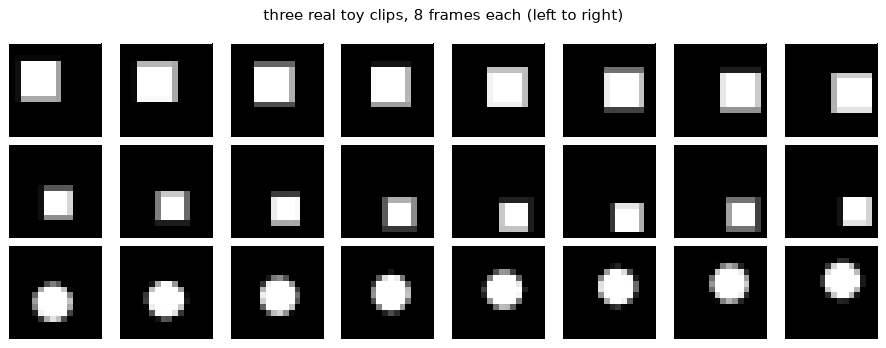

flicker of real clips (std of the object's total brightness over time, relative): 0.004
data: (2000, 8, 16, 16) = clips x frames x height x width


In [12]:
t0 = time.time()
VT, VH = 8, 16
yy, xx = np.mgrid[0:VH, 0:VH].astype(np.float32)

def make_videos(N, seed):
    rg = np.random.default_rng(seed)
    r = rg.uniform(2.2, 3.4, N); shape = rg.integers(0, 2, N)
    pos = np.stack([rg.uniform(4, VH - 4, N), rg.uniform(4, VH - 4, N)], 1)
    ang = rg.uniform(0, 2 * np.pi, N); sp = rg.uniform(0.5, 1.4, N)
    vel = np.stack([np.cos(ang), np.sin(ang)], 1) * sp[:, None]
    vid = np.zeros((N, VT, VH, VH), np.float32)
    for t in range(VT):
        dx, dy = xx[None] - pos[:, 0, None, None], yy[None] - pos[:, 1, None, None]
        d = np.where(shape[:, None, None] == 0, np.sqrt(dx ** 2 + dy ** 2), np.maximum(np.abs(dx), np.abs(dy)))
        vid[:, t] = np.clip(r[:, None, None] + 0.5 - d, 0, 1)
        pos = pos + vel
        for k in range(2):
            lo = pos[:, k] < r + 0.5; hi = pos[:, k] > VH - 1 - r - 0.5
            vel[lo | hi, k] *= -1; pos[:, k] = np.clip(pos[:, k], r + 0.5, VH - 1 - r - 0.5)
    return vid

Vtr, Vte = make_videos(2000, 10), make_videos(200, 11)
def strip(ax_row, clip):
    for t in range(VT):
        ax_row[t].imshow(clip[t], cmap="gray", vmin=0, vmax=1); ax_row[t].axis("off")
fig, ax = plt.subplots(3, VT, figsize=(10, 3.9))
for r in range(3): strip(ax[r], Vtr[r])
plt.suptitle("three real toy clips, 8 frames each (left to right)"); plt.tight_layout(); plt.show()

# how many numbers, and the flicker measure used below
def mass_flicker(v):
    m = np.clip(v, 0, 1).sum((2, 3)); return float((m.std(1) / (m.mean(1) + 1e-6)).mean())
print("flicker of real clips (std of the object's total brightness over time, relative):", round(mass_flicker(Vte), 3))
print("data:", Vtr.shape, "= clips x frames x height x width")

## 8. Toy video generation: next-frame prediction and video diffusion

Two toy generators.

**A next-frame predictor** (the video counterpart of the autoregressive family): a small convolutional network sees the two previous frames and predicts the next one, trained with mean squared error. To generate a clip, give it the first two frames and feed its own predictions back. Errors accumulate, and a regression loss with several plausible futures produces the average of them: blur.

**A video diffusion model**: the denoiser of section 4, extended to the time axis. Its blocks are **(2+1)D residual blocks** (a 3x3 spatial convolution and a temporal convolution of kernel size 3), so each frame can see its neighbours. To measure what the time layers buy, we train a **twin with temporal kernel size 1**, which has no way to exchange information between frames and so denoises 8 independent images stacked in a tensor. Both are trained for the same number of steps on the same data, then sample clips from pure noise.

**How we measure temporal consistency.** (1) **Flicker**: the standard deviation over time of the object's total brightness, divided by its mean (real clips: near 0). (2) **Optical-flow warping error**, the standard measure in video-editing papers: estimate the motion between two consecutive frames with a flow network (RAFT, section 9), warp the next frame back with that flow and compare with the current one. If the video is temporally coherent, motion explains the change and the error is small; if the objects flicker, change shape or pop in, no motion explains it and the error is large. We compute it on frames upsampled to 128 x 128 (RAFT needs at least that).

In [13]:
t0 = time.time()
from torchvision.models.optical_flow import raft_small, Raft_Small_Weights
raft = raft_small(weights=Raft_Small_Weights.DEFAULT).eval()

def to_rgb(v):                                                          # (N, T, H, W) in [0,1] -> (N, T, 3, 128, 128) in [-1,1]
    N, T = v.shape[:2]
    x = F.interpolate(torch.tensor(np.clip(v, 0, 1)).reshape(N * T, 1, VH, VH).float(), size=128, mode="bilinear", align_corners=False)
    return (x * 2 - 1).repeat(1, 3, 1, 1).reshape(N, T, 3, 128, 128)

@torch.no_grad()
def raft_flow(a, b, bs=96):                                             # a, b: (B, 3, 128, 128) -> flow a to b (B, 2, 128, 128)
    return torch.cat([raft(a[i:i + bs], b[i:i + bs])[-1] for i in range(0, len(a), bs)])

def warp(img, flow):                                                    # sample img at x + flow(x)
    B, _, H, W = img.shape
    gy, gx = torch.meshgrid(torch.arange(H).float(), torch.arange(W).float(), indexing="ij")
    grid = torch.stack([(gx + flow[:, 0]) / (W - 1) * 2 - 1, (gy + flow[:, 1]) / (H - 1) * 2 - 1], -1)
    return F.grid_sample(img, grid, align_corners=True, padding_mode="border")

def warp_error(v):
    x = to_rgb(v); N, T = x.shape[:2]
    a, b = x[:, :-1].reshape(-1, 3, 128, 128), x[:, 1:].reshape(-1, 3, 128, 128)
    fl = raft_flow(a, b)
    err = ((a - warp(b, fl)).abs() / 2).mean((1, 2, 3))                  # back to the [0,1] pixel scale
    return float(err.mean())

class NextFrame(nn.Module):
    def __init__(s, ch=32):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(2, ch, 3, padding=1), nn.ReLU(), nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(), nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(),
                              nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(), nn.Conv2d(ch, 1, 3, padding=1))
    def forward(s, x): return s.net(x)

torch.manual_seed(0)
nf = NextFrame(); opt = torch.optim.Adam(nf.parameters(), 2e-3)
V = torch.tensor(Vtr)
tt0 = time.time()
for step in range(1500):
    b = torch.randint(0, len(V), (64,)); t = torch.randint(2, VT, (64,))
    ctx = torch.stack([V[b, t - 2], V[b, t - 1]], 1); tgt = V[b, t][:, None]
    loss = F.mse_loss(nf(ctx), tgt); opt.zero_grad(); loss.backward(); opt.step()
print(f"next-frame predictor trained in {time.time() - tt0:.0f} s, final loss {loss.item():.4f}")

@torch.no_grad()
def rollout(v):
    fr = [torch.tensor(v[:, 0]), torch.tensor(v[:, 1])]
    for t in range(2, VT):
        fr.append(nf(torch.stack(fr[-2:], 1))[:, 0].clamp(0, 1))
    return torch.stack(fr, 1).numpy()

Rte = rollout(Vte)
rows = []
for h in range(2, VT):
    rows.append({"frame": h, "horizon": h - 1, "MSE next-frame model": float(((Rte[:, h] - Vte[:, h]) ** 2).mean()), "MSE copy last known frame": float(((Vte[:, 1] - Vte[:, h]) ** 2).mean()),
                 "brightness kept (pred/true)": float(Rte[:, h].sum((1, 2)).mean() / Vte[:, h].sum((1, 2)).mean())})
print(pd.DataFrame(rows).round(4).to_string(index=False))
WE_REAL = warp_error(Vte[:64])
print("next-frame rollout: flicker", round(mass_flicker(Rte), 3), "| warping error", round(warp_error(Rte[:64]), 4), "| real clips warping error", round(WE_REAL, 4))
lap("section 8 next-frame", t0)

next-frame predictor trained in 15 s, final loss 0.0029
 frame  horizon  MSE next-frame model  MSE copy last known frame  brightness kept (pred/true)
     2        1                0.0028                     0.0234                       1.0164
     3        2                0.0109                     0.0569                       1.0287
     4        3                0.0260                     0.0843                       1.0454
     5        4                0.0461                     0.1070                       1.0696
     6        5                0.0672                     0.1246                       1.1074
     7        6                0.0870                     0.1357                       1.1469


next-frame rollout: flicker 0.272 | warping error 0.0134 | real clips warping error 0.0108
[section 8 next-frame: 37 s]


**Reading.** The next-frame model beats copying the last known frame at every horizon (squared error 0.0028 against 0.023 one frame ahead), but the advantage shrinks as errors accumulate: 0.087 against 0.136 six frames ahead. The total brightness of the predicted frame drifts from 102 % to 115 % of the true one: the object smears and ghosts, which is the blur of a regression loss with a rolled-out error. The relative flicker of the rollouts is 0.28 against 0.004 for real clips, so the brightness-based measure catches it, while the optical-flow warping error (0.0134 against 0.0108 for real clips) barely does: RAFT finds a motion that explains a smeared object just as well. No single temporal metric is enough.

space-time layers (temporal kernel 3): parameters 28513, loss 0.285 -> 0.035, train 84 s, sample 2 s


per-frame layers (temporal kernel 1): parameters 25441, loss 0.275 -> 0.035, train 75 s, sample 2 s


                                              clips  flicker  optical-flow warping error
                                    real test clips    0.004                      0.0108
                                 next-frame rollout    0.283                      0.0134
    space-time layers (temporal kernel 3) diffusion    0.457                      0.0530
     per-frame layers (temporal kernel 1) diffusion    0.486                      0.1600
frames from different real clips (no temporal link)    0.266                      0.0544


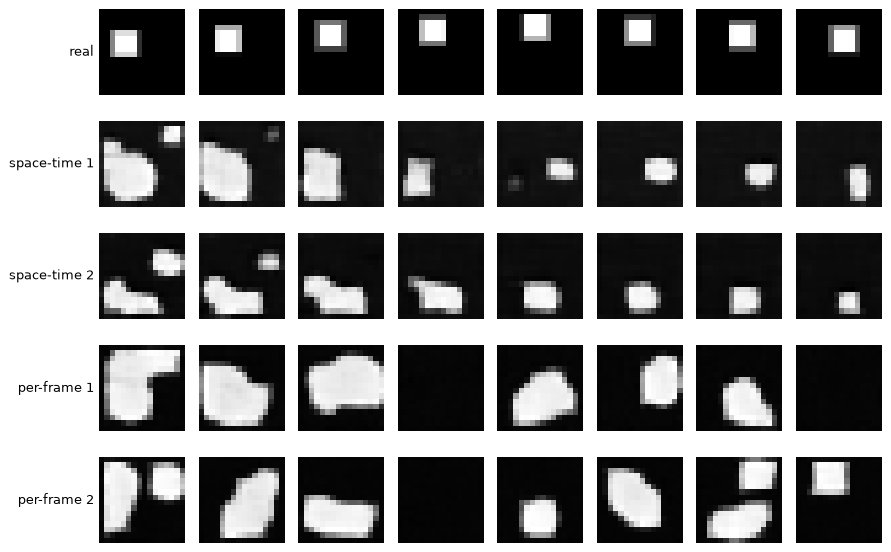

[section 8 video diffusion: 217 s]


In [14]:
t0 = time.time()
class STBlock(nn.Module):                                               # (2+1)D residual block: spatial 3x3 then temporal conv of size tk
    def __init__(s, ch, tk, ed=64):
        super().__init__()
        s.n1, s.n2 = nn.GroupNorm(4, ch), nn.GroupNorm(4, ch)
        s.s1, s.s2 = nn.Conv3d(ch, ch, (1, 3, 3), padding=(0, 1, 1)), nn.Conv3d(ch, ch, (1, 3, 3), padding=(0, 1, 1))
        s.t1, s.t2 = nn.Conv3d(ch, ch, (tk, 1, 1), padding=(tk // 2, 0, 0)), nn.Conv3d(ch, ch, (tk, 1, 1), padding=(tk // 2, 0, 0))
        s.e = nn.Linear(ed, ch)
    def forward(s, x, e):
        h = s.t1(s.s1(F.silu(s.n1(x)))) + s.e(e)[:, :, None, None, None]
        return x + s.t2(s.s2(F.silu(s.n2(h))))

class VidDenoiser(nn.Module):
    def __init__(s, tk, ch=16, nblk=3):
        super().__init__()
        s.t = nn.Sequential(nn.Linear(32, 64), nn.SiLU(), nn.Linear(64, 64))
        s.inp = nn.Conv3d(1, ch, (1, 3, 3), padding=(0, 1, 1)); s.blks = nn.ModuleList([STBlock(ch, tk) for _ in range(nblk)])
        s.out = nn.Conv3d(ch, 1, (1, 3, 3), padding=(0, 1, 1))
    def forward(s, x, t):
        e = s.t(temb(t)); h = s.inp(x)
        for b in s.blks: h = b(h, e)
        return s.out(h)

TV = 100
vb = torch.linspace(1e-4, 0.04, TV); va = 1 - vb; vab = torch.cumprod(va, 0)
Vt = (torch.tensor(Vtr)[:, None] * 2 - 1)                                # (N, 1, T, H, W) in [-1, 1]

def train_video(tk, steps=2400, seed=0, bs=32):
    torch.manual_seed(seed)
    m = VidDenoiser(tk); o = torch.optim.Adam(m.parameters(), 2e-3); ls = []
    for s_ in range(steps):
        b = torch.randint(0, len(Vt), (bs,)); x0 = Vt[b]; t = torch.randint(0, TV, (bs,)); eps = torch.randn_like(x0)
        xt = vab[t].sqrt()[:, None, None, None, None] * x0 + (1 - vab[t]).sqrt()[:, None, None, None, None] * eps
        loss = F.mse_loss(m(xt, t), eps); o.zero_grad(); loss.backward(); o.step(); ls.append(loss.item())
    return m, ls

@torch.no_grad()
def video_sample(m, n, seed=0):
    g = torch.Generator().manual_seed(seed); x = torch.randn((n, 1, VT, VH, VH), generator=g)
    for i in reversed(range(TV)):
        eps = m(x, torch.full((n,), i)); x0 = ((x - (1 - vab[i]).sqrt() * eps) / vab[i].sqrt()).clamp(-1, 1)
        ap = vab[i - 1] if i > 0 else torch.tensor(1.0)
        mean = (ap.sqrt() * vb[i] / (1 - vab[i])) * x0 + (va[i].sqrt() * (1 - ap) / (1 - vab[i])) * x
        x = mean + ((1 - ap) / (1 - vab[i]) * vb[i]).sqrt() * torch.randn(x.shape, generator=g) if i > 0 else mean
    return ((x[:, 0] + 1) / 2).clamp(0, 1).numpy()

res_v, samples = [], {}
for name, tk in [("space-time layers (temporal kernel 3)", 3), ("per-frame layers (temporal kernel 1)", 1)]:
    ts = time.time(); m, ls = train_video(tk); tr_s = time.time() - ts
    ts = time.time(); samples[name] = video_sample(m, 64); sa_s = time.time() - ts
    print(f"{name}: parameters {sum(p.numel() for p in m.parameters())}, loss {np.mean(ls[:50]):.3f} -> {np.mean(ls[-50:]):.3f}, train {tr_s:.0f} s, sample {sa_s:.0f} s")
res_v.append(("real test clips", Vte[:64])); res_v.append(("next-frame rollout", Rte[:64]))
for k, v in samples.items(): res_v.append((k + " diffusion", v))
rows = []
for nm, v in res_v:
    rows.append({"clips": nm, "flicker": round(mass_flicker(v), 3), "optical-flow warping error": round(warp_error(v), 4)})
indep = np.stack([Vte[(np.arange(64) + 7 * t) % len(Vte), t] for t in range(VT)], 1)         # frame t of each clip comes from a different real clip
rows.append({"clips": "frames from different real clips (no temporal link)", "flicker": round(mass_flicker(indep), 3), "optical-flow warping error": round(warp_error(indep), 4)})
print(pd.DataFrame(rows).to_string(index=False))

S3, S1 = samples["space-time layers (temporal kernel 3)"], samples["per-frame layers (temporal kernel 1)"]
film = [("real", Vte[0]), ("space-time 1", S3[0]), ("space-time 2", S3[1]), ("per-frame 1", S1[0]), ("per-frame 2", S1[1])]
fig, ax = plt.subplots(len(film), VT, figsize=(10, 6.4))
for r, (lab, clip) in enumerate(film): strip(ax[r], clip)
for a, (lab, _) in zip(ax[:, 0], film):
    a.axis("on"); a.set_xticks([]); a.set_yticks([]); a.set_ylabel(lab, rotation=0, ha="right", va="center")
    for sp_ in a.spines.values(): sp_.set_visible(False)
plt.tight_layout(); plt.show()
lap("section 8 video diffusion", t0)

**Reading.** Both denoisers reach the same training loss (0.035) but not the same clips. With temporal layers the warping error of the samples is 0.053; without them it is 0.160, three times worse: when every frame is denoised independently, consecutive frames disagree and no motion explains the change. That is the expected effect, measured. The caveats are as large as the effect: the space-time samples are still poor, with a warping error as high as that of real frames taken from different clips (0.054, a weak reference because RAFT can always explain two different frames by moving a disc), and a flicker of 0.46 that is higher even than that of those unrelated real frames (0.27). The flicker of the two diffusion models (0.457 and 0.486) is too close to tell apart (one seed, 28,000 parameters, 2,400 steps). What the experiment supports is narrow: temporal layers are necessary for consistency (equal training loss, very different warping error), and training loss alone does not reveal temporal quality. Look at the film strips: the real clips have one clean object, the generated ones have blobs.

## 9. Pre-trained motion models: RAFT and a video classifier

Two real pre-trained networks, both from torchvision and both running on the CPU.

**RAFT** (recurrent all-pairs field transforms, [Teed and Deng, 2020](https://arxiv.org/abs/2003.12039)) estimates **optical flow**: for every pixel of frame A, the displacement to the matching pixel of frame B. It builds a correlation volume between all pairs of pixels and refines the flow with a recurrent unit. We use the **small** variant (1 million parameters). Code and weights come through [torchvision](https://pytorch.org/vision/stable/models/raft.html) (BSD 3-Clause licence for the code; the weights were trained on the FlyingChairs and FlyingThings3D synthetic datasets, whose own terms apply). We already used it as a ruler. Now we use it as a tool: **frame interpolation**. Given frames $t-1$ and $t+1$, estimate the flow $f$ between them and build the middle frame by sampling each frame half a flow vector toward the middle and averaging. The naive baseline is to average the two frames, which gives a ghost with two half-bright objects.

**A video classifier** shows what *spatio-temporal* features capture. We take R(2+1)D-18 ([Tran et al., 2018](https://arxiv.org/abs/1711.11248)), a ResNet with (2+1)D convolutions pre-trained on Kinetics-400 (400 human-action classes, [Kay et al., 2017](https://arxiv.org/abs/1705.06950)), from torchvision ([model page](https://pytorch.org/vision/stable/models/generated/torchvision.models.video.r2plus1d_18.html); code BSD 3-Clause; the weights come from training on Kinetics, a set of YouTube clips: check their terms before commercial use). We feed it synthetic clips of a bright disc moving **left, right, up or down** (112 x 112 pixels, 8 frames), take its 512-dimensional features and train a linear probe (logistic regression, 5-fold cross-validation) to recover the direction. Then we repeat with the **frames of every clip randomly shuffled in time**: the same pixels, the same network, but no motion information. Chance is 25 %. Its Kinetics labels are meaningless for such clips; we use only the features.

                      method  PSNR (dB)
      average the two frames       24.3
RAFT flow, warp both halfway       30.9


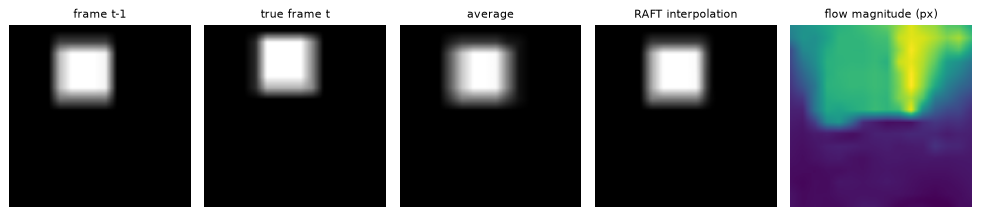

features of 320 clips in 60 s
input to the pre-trained video network  direction accuracy (5-fold)   std
              clips in the right order                        0.981 0.025
           same clips, frames shuffled                        0.544 0.032
[section 9: 77 s]


In [15]:
t0 = time.time()
# --- frame interpolation with RAFT on the held-out toy clips ---
x = to_rgb(Vte[:100])                                                    # (100, 8, 3, 128, 128) in [-1, 1]
mids = torch.arange(1, VT - 1)
a = x[:, mids - 1].reshape(-1, 3, 128, 128); b = x[:, mids + 1].reshape(-1, 3, 128, 128); truth = x[:, mids].reshape(-1, 3, 128, 128)
fl = raft_flow(a, b)
flow_mid = 0.5 * (warp(a, -0.5 * fl) + warp(b, 0.5 * fl))
avg_mid = 0.5 * (a + b)
psnr = lambda p, q: float((10 * torch.log10(4.0 / ((p - q) ** 2).mean((1, 2, 3)))).mean())            # signal range is 2 (from -1 to 1)
rows = [{"method": "average the two frames", "PSNR (dB)": round(psnr(avg_mid, truth), 1)}, {"method": "RAFT flow, warp both halfway", "PSNR (dB)": round(psnr(flow_mid, truth), 1)}]
print(pd.DataFrame(rows).to_string(index=False))
fig, ax = plt.subplots(1, 5, figsize=(11, 2.5))
k = 3
for a_, im_, nm in zip(ax, [a[k], truth[k], avg_mid[k], flow_mid[k], fl[k].norm(dim=0)], ["frame t-1", "true frame t", "average", "RAFT interpolation", "flow magnitude (px)"]):
    a_.imshow((im_[0] + 1) / 2 if im_.dim() == 3 else im_, cmap="gray" if im_.dim() == 3 else "viridis"); a_.set_title(nm, fontsize=9); a_.axis("off")
plt.tight_layout(); plt.show()

# --- a pre-trained video classifier as a feature extractor ---
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
wv = R2Plus1D_18_Weights.DEFAULT
vid = r2plus1d_18(weights=wv).eval()
MEAN, STD = torch.tensor([0.43216, 0.394666, 0.37645]).view(1, 3, 1, 1, 1), torch.tensor([0.22803, 0.22145, 0.216989]).view(1, 3, 1, 1, 1)
DIRS = {"right": (1, 0), "left": (-1, 0), "down": (0, 1), "up": (0, -1)}
def move_clips(n_per, seed, H=112, T=8):
    rg = np.random.default_rng(seed); out, lab = [], []
    gy, gx = np.mgrid[0:H, 0:H].astype(np.float32)
    for ci, (nm, (dx, dy)) in enumerate(DIRS.items()):
        for _ in range(n_per):
            p = np.array([rg.uniform(35, 77), rg.uniform(35, 77)]); r = rg.uniform(9, 14); sp = rg.uniform(5, 7)
            bg = rg.uniform(0.0, 0.25); fr = []
            for t in range(T):
                c = p + np.array([dx, dy]) * sp * (t - T / 2)
                fr.append(np.clip(bg + (1 - bg) * np.clip(r + 0.5 - np.sqrt((gx - c[0]) ** 2 + (gy - c[1]) ** 2), 0, 1), 0, 1))
            out.append(np.stack(fr)); lab.append(ci)
    return np.array(out, dtype=np.float32), np.array(lab)
Vm, ym = move_clips(40, 5)
@torch.no_grad()
def r21d_feats(v, bs=16):
    f = []
    head, vid.fc = vid.fc, nn.Identity()
    for i in range(0, len(v), bs):
        x = torch.tensor(v[i:i + bs])[:, None].repeat(1, 3, 1, 1, 1)
        f.append(vid((x - MEAN) / STD))
    vid.fc = head
    return torch.cat(f).numpy()
ts = time.time()
Vsh = np.stack([c[np.random.default_rng(i).permutation(8)] for i, c in enumerate(Vm)])
F_ok = r21d_feats(Vm); F_sh = r21d_feats(Vsh)
print(f"features of {2 * len(Vm)} clips in {time.time() - ts:.0f} s")
probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
acc_ok = cross_val_score(probe, F_ok, ym, cv=5); acc_sh = cross_val_score(probe, F_sh, ym, cv=5)
print(pd.DataFrame([{"input to the pre-trained video network": "clips in the right order", "direction accuracy (5-fold)": round(acc_ok.mean(), 3), "std": round(acc_ok.std(), 3)},
                    {"input to the pre-trained video network": "same clips, frames shuffled", "direction accuracy (5-fold)": round(acc_sh.mean(), 3), "std": round(acc_sh.std(), 3)}]).to_string(index=False))
lap("section 9", t0)

**Reading.** Frame interpolation with RAFT lifts the PSNR (peak signal-to-noise ratio, higher is better) of the middle frame from 24.3 dB (averaging, the ghost) to 30.9 dB on held-out toy clips, a gain of 6.6 dB. The scene is the best case for a flow network (one clean object, no occlusion, no motion blur, a network trained on synthetic flow datasets), so real video will give a smaller gain. The probe shows what spatio-temporal features hold: the right order gives 98.1 % direction accuracy (standard deviation 2.5 % across the five folds) against 54.4 % (3.2 %) with shuffled frames. Chance is 25 %, but shuffling keeps the **axis** of motion (positions spread horizontally or vertically) and destroys only the **sign**, so about 50 % is the expected value of a model that knows the axis and guesses the sign, which is what we see. 160 clips and a linear probe: a demonstration of the principle, not a benchmark of the network.

## 10. Modern text-to-video: diffusion Transformers on space-time latent patches

The public description of the Sora family ([Brooks et al., 2024](https://openai.com/index/video-generation-models-as-world-simulators/)) and the open systems that followed share one recipe, assembled from pieces you now know:

1. **A video autoencoder** (module 04) compresses the video in space *and* time into a **latent** video: for example 8 times smaller in height and width and 4 times in time. A 5-second 24 fps 720p clip of 120 frames becomes a latent of 30 x 90 x 160.
2. **Space-time patches.** The latent video is cut into small 3D blocks (patches), each flattened and projected to a vector: a **token**. Because a token is just a patch, one model can train on videos of any duration, resolution and aspect ratio (it only changes the number of tokens), which is the main practical argument of the report.
3. **A diffusion Transformer** (DiT, [Peebles and Xie, 2023](https://arxiv.org/abs/2212.09748)) is the denoiser: instead of a U-Net it is a stack of Transformer blocks over the patch tokens. The **diffusion step** and the **text embedding** enter through the normalisation layers (adaptive layer norm) and through cross-attention to the prompt tokens (the prompt is encoded by a large language model or a text encoder; long, descriptive captions, often written by another model, improve prompt following).
4. **Training and sampling** are the diffusion recipe of module 05 (or its flow-matching cousin), run in latent space, with classifier-free guidance. The output latent goes through the video decoder.
5. **Conditioning beyond text.** Feed frames or latents of an existing video as extra tokens and the same network does image-to-video, extension forwards or backwards, or editing.

The diagram below draws it, and the table after it counts why the design is expensive: full attention over $n$ tokens costs memory and time proportional to $n^2$.

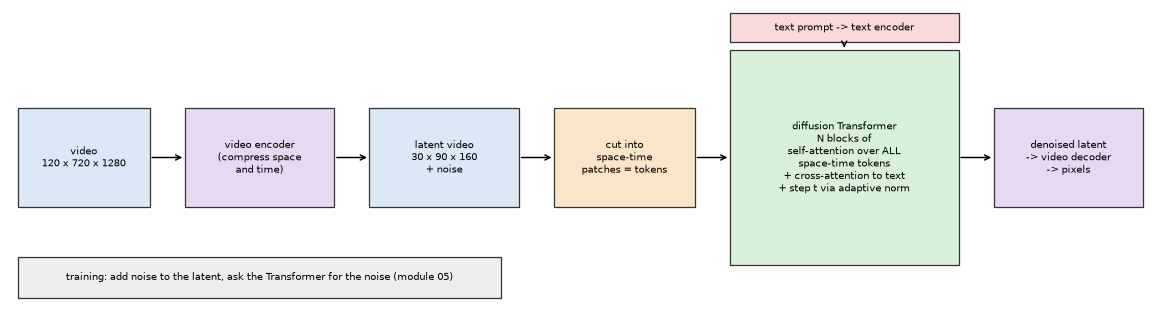

                     clip  pixels (millions)  tokens  full attention n^2 (billions)  factorised: space then time (billions)
   2 s, 24 fps, 256 x 256                  3    3072                           0.01                                   0.001
   5 s, 24 fps, 480 x 854                 49   47700                           2.28                                   0.077
  5 s, 24 fps, 720 x 1280                111  108000                          11.66                                   0.392
20 s, 24 fps, 1080 x 1920                995  964800                         930.84                                   7.873
for 720p, one token stands for 3072 raw colour values (4 frames x 16 x 16 pixels x 3 channels)


In [16]:
fig, ax = plt.subplots(figsize=(13, 3.6)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 3.6)
def box(x, y, w, h, txt, fc):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec="#333", lw=1)); ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=8)
def arrow(x0, y0, x1, y1): ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.2))
box(0.1, 1.2, 1.5, 1.2, "video\n120 x 720 x 1280", "#dbe9f6"); arrow(1.6, 1.8, 2.0, 1.8)
box(2.0, 1.2, 1.7, 1.2, "video encoder\n(compress space\nand time)", "#e8d9f3"); arrow(3.7, 1.8, 4.1, 1.8)
box(4.1, 1.2, 1.7, 1.2, "latent video\n30 x 90 x 160\n+ noise", "#dbe9f6"); arrow(5.8, 1.8, 6.2, 1.8)
box(6.2, 1.2, 1.6, 1.2, "cut into\nspace-time\npatches = tokens", "#fbe5c8"); arrow(7.8, 1.8, 8.2, 1.8)
box(8.2, 0.5, 2.6, 2.6, "diffusion Transformer\nN blocks of\nself-attention over ALL\nspace-time tokens\n+ cross-attention to text\n+ step t via adaptive norm", "#d9f0d9"); arrow(10.8, 1.8, 11.2, 1.8)
box(11.2, 1.2, 1.7, 1.2, "denoised latent\n-> video decoder\n-> pixels", "#e8d9f3")
box(8.2, 3.2, 2.6, 0.35, "text prompt -> text encoder", "#f9d9d9"); arrow(9.5, 3.2, 9.5, 3.1)
box(0.1, 0.1, 5.5, 0.5, "training: add noise to the latent, ask the Transformer for the noise (module 05)", "#eeeeee")
plt.tight_layout(); plt.show()

def n_tokens(frames, h, w, ct=4, cs=8, p=2): return (frames // ct) * (h // cs // p) * (w // cs // p)
rows = []
for nm, fr, h, w in [("2 s, 24 fps, 256 x 256", 48, 256, 256), ("5 s, 24 fps, 480 x 854", 120, 480, 854), ("5 s, 24 fps, 720 x 1280", 120, 720, 1280), ("20 s, 24 fps, 1080 x 1920", 480, 1080, 1920)]:
    n = n_tokens(fr, h, w); ns = (h // 16) * (w // 16); nt = fr // 4
    rows.append({"clip": nm, "pixels (millions)": round(fr * h * w / 1e6), "tokens": n, "full attention n^2 (billions)": round(n ** 2 / 1e9, 2),
                 "factorised: space then time (billions)": round((nt * ns ** 2 + ns * nt ** 2) / 1e9, 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("for 720p, one token stands for", round(120 * 720 * 1280 * 3 / n_tokens(120, 720, 1280)), "raw colour values (4 frames x 16 x 16 pixels x 3 channels)")

**Reading.** The numbers explain the architecture. A 5-second 720p clip becomes 108,000 tokens, so full attention has 11.7 billion pairwise scores per head and layer, and a 20-second 1080p clip has 965,000 tokens and 931 billion: quadratic growth is the central constraint. Attending first within each frame and then across time costs 0.39 billion for the 720p clip, 30 times less, which is why the first video diffusion models factorised attention, and why the systems that use full attention need heavy compression, efficient kernels and many accelerators. The compression factors used here (8 times in space, 4 in time, patches of 2 by 2) are typical of open systems and **assumptions of this notebook**: the Sora report does not publish its exact numbers.

## 11. Provenance, watermarking and safety

Realistic synthetic voices and video are useful (dubbing, accessibility, restoring a voice lost to illness, film previsualisation) and dangerous in the same breath. The risks you should be able to name:

* **Impersonation and fraud.** A few seconds of a real voice are enough for a voice-cloning system to speak in it (see module 07 of Neural Networks 1002); phone scams using cloned voices of relatives or executives are documented. Synthetic video of a real person saying or doing something they never did (a **deepfake**) is used for fraud, harassment, non-consensual intimate imagery and political disinformation.
* **Consent and likeness.** Using a person's voice or face without consent is a harm even when no one is deceived. Many jurisdictions give people rights over their likeness; models and services increasingly require proof of consent for voice cloning.
* **Copyright and training data.** Music and film are heavily protected works. Models trained on licensed data (as MusicGen) differ legally and ethically from models trained on scraped data, and **model weights can carry non-commercial licences that follow the output into your product**. Whether the output of a model can reproduce training material (memorisation) is an open measurement problem.
* **The liar's dividend.** When anything can be faked, real recordings can be dismissed as fake.

Technical countermeasures all have limits:

* **Provenance metadata.** C2PA ([Coalition for Content Provenance and Authenticity](https://c2pa.org/)) attaches a cryptographically signed history to a file ("Content Credentials"). It proves where a file came from when it is intact and honest, and says nothing once the metadata is stripped (a screenshot, a re-encode).
* **Watermarks inside the signal.** An imperceptible pattern added to the audio or pixels that a detector can find later and that should survive compression, noise and editing. Learned audio watermarks such as AudioSeal ([San Roman et al., 2024](https://arxiv.org/abs/2401.17264), [code](https://github.com/facebookresearch/audioseal)) localise watermarked segments at the sample level; Google DeepMind's [SynthID](https://deepmind.google/models/synthid/) does it for images, audio, video and text ([Dathathri et al., 2024](https://doi.org/10.1038/s41586-024-08025-4) for text). Watermarks only help when the *generator* applies them, so open models and bad actors escape them, and a determined attacker can often remove or forge them.
* **Detectors** that classify "real versus synthetic" generalise poorly to new generators and are in an arms race with them.
* **Rules.** The EU AI Act asks providers and deployers to mark synthetic audio, image and video content and to disclose deepfakes ([Article 50](https://artificialintelligenceact.eu/article/50/)). See also [module 12 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/12-responsible-ai/) on responsible AI.

To feel what a watermark is, we build the simplest one, a **spread-spectrum** watermark: add a very quiet secret pseudo-random noise (the key is its seed, band-limited to below 3.5 kHz) to the audio, and detect it by **correlating** the audio with the secret noise: if the watermark is there, the correlation, expressed in standard deviations of what random chance gives (a $z$-score), is large; for a wrong key it is around zero. We test it on a 4 second MusicGen clip against some common edits. It is a toy: a learned watermark like AudioSeal is much more robust and can be localised.

In [17]:
t0 = time.time()
x = clips16[0].astype(np.float64); x = x / np.abs(x).max(); N = len(x)
BP = sps.butter(6, 3500, "lowpass", fs=16000, output="sos")
def key_noise(key):
    w = sps.sosfilt(BP, np.random.default_rng(key).standard_normal(N)); return w / w.std()
def embed(x, key, snr_db=20):
    return x + key_noise(key) * x.std() * 10 ** (-snr_db / 20)
def zs(y, key):
    w = key_noise(key); c = (y * w).sum() / (np.linalg.norm(y) * np.linalg.norm(w)); return float(c * np.sqrt(N))
KEY = 1234
y = embed(x, KEY, 20)
print("watermark level: signal-to-watermark ratio 20 dB; listening difference is a faint hiss")
edits = {
    "no edit": lambda s: s,
    "added noise (10 dB SNR)": lambda s: s + np.random.default_rng(7).standard_normal(N) * s.std() * 10 ** (-10 / 20),
    "resample 16 -> 8 -> 16 kHz": lambda s: sps.resample_poly(sps.resample_poly(s, 1, 2), 2, 1)[:N],
    "8-bit quantisation": lambda s: np.round(s / np.abs(s).max() * 127) / 127 * np.abs(s).max(),
    "cut the first 0.5 s": lambda s: np.concatenate([s[8000:], np.zeros(8000)]),
    "shift by 3 samples": lambda s: np.roll(s, 3),
}
wrong = [zs(y, k) for k in range(1, 201)]
rows = []
for nm, f in edits.items():
    e = f(y); rows.append({"edit applied to the watermarked clip": nm, "z-score, right key": round(zs(e, KEY), 1), "z-score, unmarked clip": round(zs(f(x), KEY), 1)})
print(pd.DataFrame(rows).to_string(index=False))
print(f"200 wrong keys on the watermarked clip: z-scores mean {np.mean(wrong):.2f}, std {np.std(wrong):.2f}, max {np.max(wrong):.2f} (the largest wrong-key score is the null level; the detection threshold is set above it, at 8)")
play(x, 16000, "clip without watermark"); play(y, 16000, "clip with the watermark (20 dB below the music)")
lap("section 11", t0)

watermark level: signal-to-watermark ratio 20 dB; listening difference is a faint hiss


edit applied to the watermarked clip  z-score, right key  z-score, unmarked clip
                             no edit                25.3                     0.4
             added noise (10 dB SNR)                24.1                     0.2
          resample 16 -> 8 -> 16 kHz                25.0                     0.4
                  8-bit quantisation                25.3                     0.4
                 cut the first 0.5 s                -0.6                    -0.8
                  shift by 3 samples                -3.9                     0.8
200 wrong keys on the watermarked clip: z-scores mean -0.11, std 1.62, max 4.28 (the largest wrong-key score is the null level; the detection threshold is set above it, at 8)
clip without watermark


clip with the watermark (20 dB below the music)


[section 11: 0 s]


**Reading.** With the right key the detector gives a z-score of 25 on the watermarked clip, 24 to 25 after noise at 10 dB, resampling through 8 kHz and 8-bit quantisation, and 0.2 to 0.4 on the clip without the watermark; 200 wrong keys give scores with mean -0.1 and standard deviation 1.6 (larger than 1 because music is not white noise), with a maximum of 4.3, so a threshold of 8 separates them. It fails completely when the clip is cut or shifted by only 3 samples (z of -0.6 and -3.9): the correlation needs the audio and the key aligned, and real systems search over shifts or use a learned detector that works frame by frame. It survives the low-pass of the resampling only because we put the watermark below 3.5 kHz by design: a 2 kHz low-pass would erase part of it, and anyone who knows the method can subtract or forge it. This is the reason real watermarks are learned jointly with attacks, and the reason none of them is a guarantee.

## 12. Key takeaways, exercises, references

**Key takeaways**

* Audio and video are generated through **compact representations**: spectrograms, discrete codec tokens, space-time latents. The raw signal is too long. The representation sets the ceiling of quality, and the generator (autoregressive or diffusion) sets the cost and the control.
* The **STFT** has a time-frequency trade-off (measured above), the **mel spectrogram** discards phase, and a **vocoder** (Griffin-Lim, or a neural one such as HiFi-GAN) has to invent it back; the neural one does it faster and more naturally, at the price of a training domain.
* A **neural codec** turns audio into a grid of integers at a measurable bitrate, so audio generation becomes language modelling (MusicGen) and quality degrades smoothly as you remove codebooks.
* **Autoregressive over tokens** and **diffusion over spectrograms** both work on a toy; what each wins or loses is in the tables, not in slogans, and with few runs the differences must be read with their noise.
* **Evaluation is the hard part.** Fréchet distances depend on the embedding network and on the sample size; listening tests remain the reference. Report what a metric cannot see.
* **Video = frames + time.** Without a mechanism that exchanges information across frames, generated clips flicker; temporal convolutions, temporal attention or full space-time attention are the three answers, with a growing cost. Sora-style systems tokenise a compressed latent video into space-time patches and denoise it with a Transformer.
* Our video toys are illustrative: 16 x 16 pixels, one object, constant velocity. They show that the measurements (flicker, warping error) detect the missing time layers, not that this model could generate natural video.
* **Provenance and safety** are part of the engineering: weights licences, consent, watermarking and metadata (each with known limits), and disclosure rules.

**Exercises**

1. In section 2, repeat the codec table with a clip of speech-like sound (for example a vibrato note with a fast amplitude modulation) and with white noise. Which signal is cheapest to compress and which is hardest for EnCodec, and why?
2. Replace the Hann window in `stft` by a rectangular window and rerun the two-tone experiment. How do the number of peaks and the click width change? What does spectral leakage have to do with it?
3. In section 3, vary the number of Griffin-Lim iterations (10, 30, 100, 300) and plot the multi-resolution log-spectral distance. Does the metric keep improving while the sound still seems "phasey"? Why might a metric on magnitudes miss it?
4. In section 4, change the number of k-means centroids $K$ to 16 and 256. How do the "AR ceiling" row and the autoregressive row move? Then use two codebooks (quantise the residual of the first with a second k-means) and see whether the ceiling improves.
5. Train the diffusion model with 800 steps instead of 2,000 and with 4,000 steps. Is the Fréchet distance monotone? Repeat with three seeds and report mean and spread.
6. Sample the autoregressive model with temperature 0.7 and 1.3. Which of the three measures of section 4 moves, and which direction does the "diversity versus fidelity" trade-off take?
7. In section 5, change the guidance scale to 1 and to 7 and generate with the same seed. What changes in the descriptors and in what you hear? Add a prompt for a style you expect to be poorly covered by the training data and say what you observe honestly.
8. In section 6, compute the Fréchet distance with 10 generated sounds per type instead of 30. How large is its random spread compared with the difference between the autoregressive and diffusion rows?
9. Section 8: add a second moving object to the toy clips. Which model breaks first, the next-frame predictor or the video diffusion? Add a full temporal attention layer (over the 8 frames, at every spatial position) to the video denoiser and see whether it helps more than the temporal convolution.
10. Section 9: interpolate between frames that are 4 apart instead of 2. When does RAFT-based interpolation stop beating plain averaging?
11. Section 11: apply a 4 kHz low-pass filter, then a 2 kHz one, to the watermarked audio. At which point does the detector fail, and how would you design a watermark that survives it?
12. Read the model card of any open text-to-video model and list three things it says about training data, licence and intended use. What would you need to check before using its output commercially?

**References**

* van den Oord, A. et al. (2016). WaveNet: a generative model for raw audio. arXiv:1609.03499: https://arxiv.org/abs/1609.03499
* Kong, J., Kim, J. and Bae, J. (2020). HiFi-GAN: generative adversarial networks for efficient and high fidelity speech synthesis. *NeurIPS*. arXiv:2010.05646: https://arxiv.org/abs/2010.05646
* Défossez, A., Copet, J., Synnaeve, G. and Adi, Y. (2022). High fidelity neural audio compression (EnCodec). arXiv:2210.13438: https://arxiv.org/abs/2210.13438 ; code (MIT): https://github.com/facebookresearch/encodec ; model card: https://huggingface.co/facebook/encodec_24khz
* Copet, J. et al. (2023). Simple and controllable music generation (MusicGen). *NeurIPS*. arXiv:2306.05284: https://arxiv.org/abs/2306.05284 ; model card (weights CC-BY-NC 4.0): https://huggingface.co/facebook/musicgen-small ; code (MIT): https://github.com/facebookresearch/audiocraft
* Kong, Z., Ping, W., Huang, J., Zhao, K. and Catanzaro, B. (2021). DiffWave: a versatile diffusion model for audio synthesis. *ICLR*. arXiv:2009.09761: https://arxiv.org/abs/2009.09761
* Ho, J. et al. (2022). Video diffusion models. *NeurIPS*. arXiv:2204.03458: https://arxiv.org/abs/2204.03458
* Teed, Z. and Deng, J. (2020). RAFT: recurrent all-pairs field transforms for optical flow. *ECCV*. arXiv:2003.12039: https://arxiv.org/abs/2003.12039 ; torchvision model page: https://pytorch.org/vision/stable/models/raft.html
* Brooks, T. et al. (2024). Video generation models as world simulators. OpenAI technical report: https://openai.com/index/video-generation-models-as-world-simulators/
* Kilgour, K., Zuluaga, M., Roblek, D. and Sharifi, M. (2019). Fréchet audio distance: a reference-free metric for evaluating music enhancement algorithms. *Interspeech*. arXiv:1812.08466: https://arxiv.org/abs/1812.08466
* Griffin, D. and Lim, J. (1984). Signal estimation from modified short-time Fourier transform. *IEEE Trans. Acoustics, Speech, and Signal Processing* 32(2), 236-243: https://doi.org/10.1109/TASSP.1984.1164317
* Ao, J. et al. (2022). SpeechT5: unified-modal encoder-decoder pre-training for spoken language processing. *ACL*. arXiv:2110.07205: https://arxiv.org/abs/2110.07205 ; HiFi-GAN checkpoint (MIT): https://huggingface.co/microsoft/speecht5_hifigan
* Borsos, Z. et al. (2022). AudioLM: a language modeling approach to audio generation. arXiv:2209.03143: https://arxiv.org/abs/2209.03143
* Evans, Z. et al. (2024). Fast timing-conditioned latent audio diffusion (Stable Audio). *ICML*. arXiv:2402.04825: https://arxiv.org/abs/2402.04825
* Tran, D. et al. (2018). A closer look at spatiotemporal convolutions for action recognition (R(2+1)D). *CVPR*. arXiv:1711.11248: https://arxiv.org/abs/1711.11248 ; torchvision model page: https://pytorch.org/vision/stable/models/generated/torchvision.models.video.r2plus1d_18.html
* Kay, W. et al. (2017). The Kinetics human action video dataset. arXiv:1705.06950: https://arxiv.org/abs/1705.06950
* Peebles, W. and Xie, S. (2023). Scalable diffusion models with Transformers (DiT). *ICCV*. arXiv:2212.09748: https://arxiv.org/abs/2212.09748
* San Roman, R. et al. (2024). Proactive detection of voice cloning with localized watermarking (AudioSeal). *ICML*. arXiv:2401.17264: https://arxiv.org/abs/2401.17264 ; code: https://github.com/facebookresearch/audioseal
* Dathathri, S. et al. (2024). Scalable watermarking for identifying large language model outputs (SynthID-Text). *Nature* 634, 818-823: https://doi.org/10.1038/s41586-024-08025-4 ; SynthID overview: https://deepmind.google/models/synthid/
* C2PA (Coalition for Content Provenance and Authenticity), Content Credentials: https://c2pa.org/
* European Union, AI Act, Article 50 (transparency obligations for providers and deployers of certain AI systems): https://artificialintelligenceact.eu/article/50/